# Démo 6 · Les images comme données : des filtres aux réseaux convolutifs

Pour un ordinateur, une photo n’est qu’un tableau de nombres. Ce notebook part de ces nombres. Avec OpenCV, nous les transformons, nous les filtrons et nous en tirons des **caractéristiques** : contraste, contours, gradients. C’est la vision par ordinateur classique, celle du cours 16. À la fin, nous entraînons un petit **réseau convolutif** sur des chiffres manuscrits. Il apprend tout seul des filtres semblables aux nôtres, et nous mesurons ce que nos outils lui apportent quand les données étiquetées manquent.

À la fin, vous serez capables de :

- Lire, afficher et enregistrer des images avec OpenCV sans mélanger les canaux.
- Appliquer des opérations ponctuelles et des filtres, et expliquer ce que fait un noyau.
- Écrire une convolution vous-mêmes.
- Extraire des contours et des gradients, et expliquer pourquoi on lisse avant de dériver.
- Déformer des images et construire une augmentation de données.
- Expliquer ce qu’apprend la couche de convolution d’un CNN, et quand nos caractéristiques l’aident.

| Section | Contenu |
|---|---|
| A. Une image, c’est un tableau | Pixels, canaux, type `uint8`, lecture avec OpenCV, BGR, espaces de couleurs |
| B. Transformer chaque pixel | Opérations ponctuelles, histogrammes, seuillage, morphologie |
| C. Filtrer : la convolution | Moyenne à la main, noyaux, débruitage, corrélation, équivariance |
| D. Les contours, une première caractéristique | Dérivées, lissage, Sobel, gradient, Canny |
| E. Déformer et augmenter | Redimensionner, tourner, redresser, augmenter |
| F. Des caractéristiques à un réseau convolutif | Un CNN sur MNIST, ses filtres, ce que nos caractéristiques lui apportent |

Exécutez les cellules dans l’ordre et lisez chaque résultat. Essayez chaque exercice **À vous** avant d’ouvrir sa réponse de référence.

## Configuration : Colab ou en local

Le notebook fonctionne sur macOS, Linux et Windows, sans carte graphique.

**Google Colab (le plus simple) :** [ouvrez le notebook dans Colab](https://colab.research.google.com/github/milarobotlearningcourse/data_science/blob/main/demo_6/notebooks/fr/01_caracteristiques_images_cnn.ipynb). Rien à installer : OpenCV, scikit-image et PyTorch y sont déjà.

**En local :** lancez `uv sync --group vision` à la racine du dépôt `ift3700-6758`, puis sélectionnez le noyau `.venv`. Consultez le [README du dépôt](../../../README.md) au besoin. Les sections A à E n’ont besoin que de `uv sync`; le groupe `vision` ajoute PyTorch pour la section F.

Toutes les images des sections A à E viennent de `skimage.data` : elles sont fournies avec scikit-image, sans téléchargement. Seule la section F télécharge les chiffres MNIST (environ 12 Mo).

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import FloatSlider, IntSlider, interact
from matplotlib_inline.backend_inline import set_matplotlib_formats
from skimage import data

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})  # figures en JPEG, un peu plus petites :
plt.rcParams["figure.dpi"] = 80                             # le notebook reste léger

# Les fichiers produits vont dans data/ à la racine du dépôt (ignoré par Git), ou dans ./data sur Colab.
ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = ROOT / "data"


def show(*images, titles=None, size=3.2):
    """Affiche des images côte à côte. Les images en couleur doivent être en RGB."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), squeeze=False)
    for i, (ax, image) in enumerate(zip(axes[0], images)):
        if image.ndim == 3:
            ax.imshow(image)
        elif image.dtype == np.uint8:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)  # 0 = noir, 255 = blanc
        else:
            ax.imshow(image, cmap="gray")  # nombres réels : l'échelle va du minimum au maximum
        if titles is not None:
            ax.set_title(titles[i], fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def spaced(number):  # 1234567 -> "1 234 567"
    return f"{number:,}".replace(",", " ")

OpenCV 4.11.0 | NumPy 1.26.4


## Ce que nous allons faire

Le cours distingue deux choses :

- le **traitement d’images** produit une nouvelle image à partir d’une image (image → image) : la rendre plus nette, en retirer le bruit, en extraire les contours;
- la **vision par ordinateur** cherche à comprendre ce que l’image contient (image → classe) : y a-t-il une moto sur cette photo ?

Les deux se rejoignent dans la chaîne de traitement du cours, illustrée ci-dessous sur une vraie photo. Les sections A à E couvrent les trois premières étapes; la section F ajoute la quatrième.

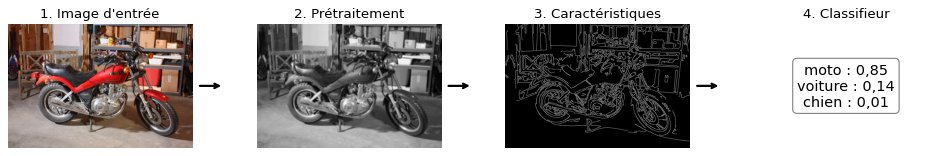

In [2]:
moto = data.stereo_motorcycle()[0]                   # une photo en couleur (RGB)
gray = cv2.cvtColor(moto, cv2.COLOR_RGB2GRAY)
smooth = cv2.GaussianBlur(gray, (5, 5), 1.5)         # prétraitement : niveaux de gris, puis flou léger
edges = cv2.Canny(smooth, 50, 150)                   # caractéristiques : les contours

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, image, title in zip(axes, [moto, smooth, edges], ["1. Image d'entrée", "2. Prétraitement", "3. Caractéristiques"]):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
axes[3].text(0.5, 0.5, "moto : 0,85\nvoiture : 0,14\nchien : 0,01", ha="center", va="center", fontsize=13,
             bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "gray"})
axes[3].set_title("4. Classifieur")
axes[3].set_box_aspect(moto.shape[0] / moto.shape[1])  # même hauteur que les images
axes[3].axis("off")
for ax in axes[:3]:
    ax.annotate("", xy=(1.17, 0.5), xytext=(1.03, 0.5), xycoords="axes fraction",
                arrowprops={"arrowstyle": "->", "lw": 2})
plt.subplots_adjust(wspace=0.35)
plt.show()

Les probabilités du classifieur sont inventées : il n’y a pas encore de modèle. Nous en entraînerons un vrai à la section F.

## A. Une image, c’est un tableau

### Des nombres dans une grille

Chargeons deux images de scikit-image : `camera`, en niveaux de gris, et `astronaut`, en couleur.

camera     forme (512, 512), type uint8, valeurs de 0 à 255
astronaut  forme (512, 512, 3), type uint8, valeurs de 0 à 255


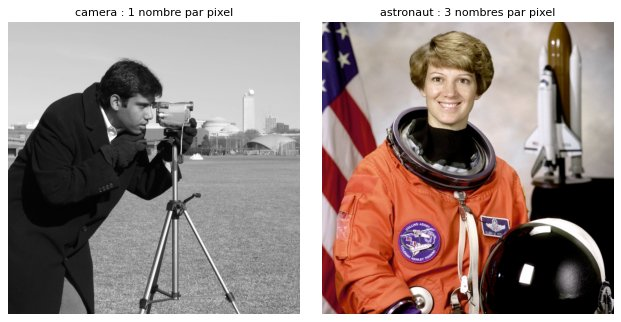

In [3]:
camera = data.camera()
astronaut = data.astronaut()

for name, image in [("camera", camera), ("astronaut", astronaut)]:
    print(f"{name:10} forme {image.shape}, type {image.dtype}, valeurs de {image.min()} à {image.max()}")

show(camera, astronaut, titles=["camera : 1 nombre par pixel", "astronaut : 3 nombres par pixel"], size=4)

Une image en niveaux de gris est un tableau NumPy à deux dimensions, `(hauteur, largeur)`. Chaque case est un **pixel** : son intensité va de 0 (noir) à 255 (blanc). Le type `uint8` (entier non signé sur 8 bits) prend exactement ces 256 valeurs, sur un octet.

Une image en couleur ajoute une troisième dimension : trois nombres par pixel, un par **canal** (rouge, vert, bleu).

Regardons de près un carré de 8 × 8 pixels, à un endroit où l’on passe brusquement du clair au sombre : le bord d’un pied du trépied.

[[218 202 252 245  97  26  15  14]
 [226 227 251 228  57  25  21  28]
 [214 246 251 195  46  32  32  38]
 [206 253 250 147  42  32  32  31]
 [216 252 242  95  36  31  30  22]
 [236 250 222  61  31  28  27  19]
 [251 249 184  50  31  29  25  19]
 [253 249 135  41  29  28  24  19]]


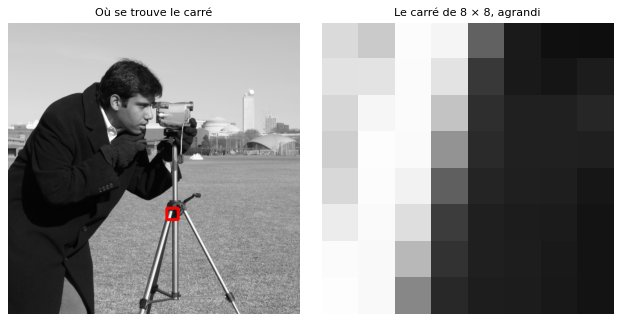

In [4]:
top, left = 332, 284
crop = camera[top : top + 8, left : left + 8]
print(crop)

framed = cv2.cvtColor(camera, cv2.COLOR_GRAY2RGB)
cv2.rectangle(framed, (left - 6, top - 6), (left + 14, top + 14), (255, 0, 0), 3)  # attention : (x, y), pas (ligne, colonne)
show(framed, crop, titles=["Où se trouve le carré", "Le carré de 8 × 8, agrandi"], size=4)

### Une image comme une fonction

On peut aussi voir l’image comme une fonction $f(x, y)$ qui donne l’intensité au point $(x, y)$. En suivant une seule ligne de l’image, on obtient une courbe. Les changements brusques de cette courbe sont les **contours**; nous y reviendrons à la section D.

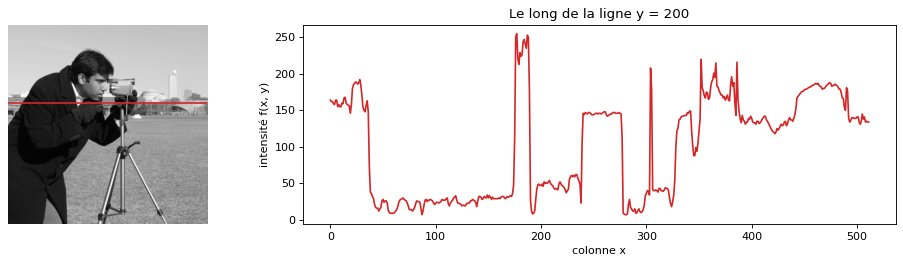

In [5]:
row = 200
fig, (ax_image, ax_profile) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 2]})
ax_image.imshow(camera, cmap="gray", vmin=0, vmax=255)
ax_image.axhline(row, color="tab:red")
ax_image.axis("off")
ax_profile.plot(camera[row], color="tab:red")
ax_profile.set(xlabel="colonne x", ylabel="intensité f(x, y)", title=f"Le long de la ligne y = {row}")
plt.tight_layout()
plt.show()

### Les canaux

Chaque canal d’une image en couleur est lui-même une image en niveaux de gris : plus il est clair, plus la couleur correspondante est présente. La combinaison orange de l’astronaute est très claire dans le canal rouge, plus sombre dans le vert, et plus sombre encore dans le bleu.

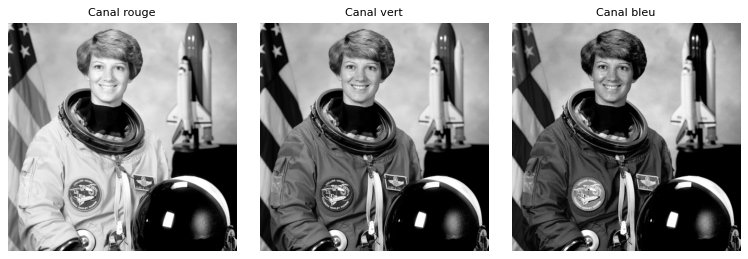

In [6]:
show(astronaut[..., 0], astronaut[..., 1], astronaut[..., 2], titles=["Canal rouge", "Canal vert", "Canal bleu"])

### Lire et enregistrer avec OpenCV

OpenCV lit une image avec `cv2.imread` et l’enregistre avec `cv2.imwrite`. Un indicateur choisit le format de lecture :

- `cv2.IMREAD_COLOR`, par défaut : trois canaux de couleur;
- `cv2.IMREAD_GRAYSCALE` : un seul canal, en niveaux de gris;
- `cv2.IMREAD_UNCHANGED` : l’image telle quelle, y compris le canal alpha (la transparence) s’il existe.

**Attention : OpenCV range les canaux dans l’ordre BGR (bleu, vert, rouge)**, pour des raisons historiques. scikit-image et matplotlib utilisent RGB. C’est la source d’erreur la plus fréquente avec OpenCV.

IMREAD_COLOR     : (512, 512, 3)
IMREAD_GRAYSCALE : (512, 512)
Fichier absent   : None


[ WARN:0@0.932] global loadsave.cpp:268 findDecoder imread_('pas_de_fichier.png'): can't open/read file: check file path/integrity


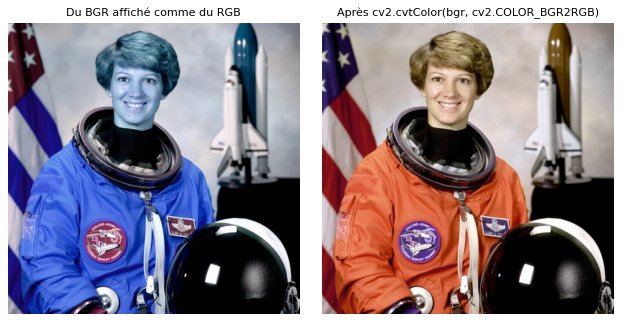

In [7]:
path = DATA_DIR / "processed" / "astronaut.png"
path.parent.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(path), cv2.cvtColor(astronaut, cv2.COLOR_RGB2BGR))  # OpenCV attend du BGR

bgr = cv2.imread(str(path))  # IMREAD_COLOR par défaut : renvoie du BGR
gray_from_disk = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
print("IMREAD_COLOR     :", bgr.shape)
print("IMREAD_GRAYSCALE :", gray_from_disk.shape)
print("Fichier absent   :", cv2.imread("pas_de_fichier.png"))  # pas d'exception : None

show(bgr, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB),
     titles=["Du BGR affiché comme du RGB", "Après cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)"], size=4)

Remarquez la troisième ligne : avec un mauvais chemin, `cv2.imread` ne lève pas d’exception. Il affiche au mieux un avertissement et renvoie `None`. L’erreur apparaît plus loin, souvent loin de sa cause. Vérifiez toujours le résultat d’une lecture.

### Deux pièges avec les nombres

**1. Largeur et hauteur.** NumPy décrit une image par `(lignes, colonnes)`, c’est-à-dire `(hauteur, largeur)`. Les fonctions d’OpenCV qui prennent une taille ou un point attendent `(largeur, hauteur)` ou `(x, y)`, comme `cv2.rectangle` plus haut.

**2. Le débordement du `uint8`.** Un `uint8` ne dépasse pas 255. NumPy « fait le tour » : 250 + 100 donne 94, car 350 − 256 = 94. OpenCV, lui, **sature** à 255.

cv2.resize(camera, (200, 100)).shape = (100, 200)   <- NumPy : (lignes, colonnes)

[200, 250] + 100 avec NumPy : [44 94]
[200, 250] + 100 avec OpenCV : [255 255]


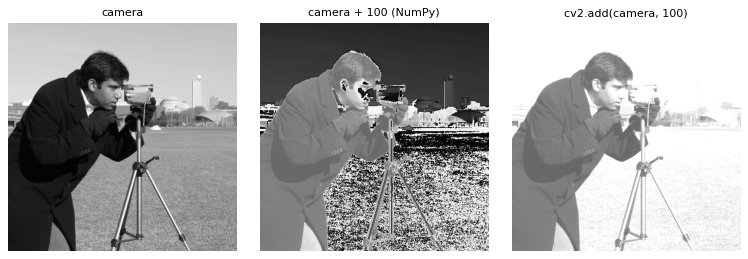

In [8]:
small = cv2.resize(camera, (200, 100))  # OpenCV : (largeur, hauteur)
print("cv2.resize(camera, (200, 100)).shape =", small.shape, "  <- NumPy : (lignes, colonnes)")

values = np.array([[200, 250]], dtype=np.uint8)  # une image de 1 × 2 pixels : OpenCV attend des tableaux 2D
print("\n[200, 250] + 100 avec NumPy :", (values + 100).ravel())
print("[200, 250] + 100 avec OpenCV :", cv2.add(values, 100).ravel())

show(camera, camera + 100, cv2.add(camera, 100), titles=["camera", "camera + 100 (NumPy)", "cv2.add(camera, 100)"])

Avec NumPy, les zones les plus claires deviennent noires. Pour calculer sans surprise, convertissez en réels (`image.astype(np.float64)`), calculez, puis ramenez entre 0 et 255 avec `np.clip` avant de revenir en `uint8`. C’est ce que nous ferons à la section B.

### Les espaces de couleurs

RGB n’est pas la seule façon de décrire une couleur. L’espace **HSV** sépare la **teinte** (*hue* : rouge, orange, vert…), la **saturation** (vive ou terne) et la **valeur** (claire ou sombre). Dans OpenCV, la teinte va de 0 à 179 (des demi-degrés, pour tenir dans un `uint8`).

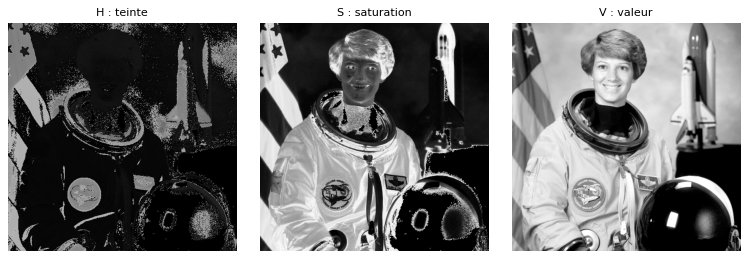

In [9]:
hsv = cv2.cvtColor(astronaut, cv2.COLOR_RGB2HSV)
show(hsv[..., 0], hsv[..., 1], hsv[..., 2], titles=["H : teinte", "S : saturation", "V : valeur"])

En RGB, l’orange mélange les trois canaux. En HSV, c’est simplement un intervalle de teinte. `cv2.inRange` garde les pixels dont les trois valeurs tombent dans un intervalle, et `cv2.bitwise_and` applique ce masque à l’image.

19% des pixels sont dans l'intervalle


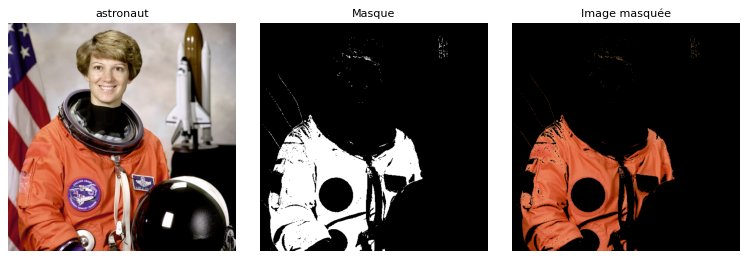

In [10]:
lower, upper = (5, 150, 100), (18, 255, 255)  # teinte orange, couleur vive, assez claire
mask = cv2.inRange(hsv, lower, upper)          # 255 si le pixel est dans l'intervalle, 0 sinon
orange_only = cv2.bitwise_and(astronaut, astronaut, mask=mask)

print(f"{(mask > 0).mean():.0%} des pixels sont dans l'intervalle")
show(astronaut, mask, orange_only, titles=["astronaut", "Masque", "Image masquée"])

Ce masque est une première **caractéristique** : il regroupe les pixels selon une propriété, ici leur couleur. Le cours parle de segmentation non contextuelle : chaque pixel est jugé seul, sans regarder ses voisins.

### À vous : BGR → RGB à la main

Écrivez `bgr_to_rgb` sans utiliser `cv2.cvtColor`. Une ligne suffit. La cellule suivante vérifie votre réponse.

In [11]:
def bgr_to_rgb(image):
    # image : tableau (hauteur, largeur, 3) en BGR
    # Votre code ici : remplacez pass, puis renvoyez la même image en RGB.
    pass

In [12]:
result = bgr_to_rgb(bgr)

if result is None:
    print("La fonction n'est pas encore complétée.")
else:
    assert result.shape == bgr.shape, "La forme doit rester (hauteur, largeur, 3)."
    assert np.array_equal(result, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)), "Les canaux ne sont pas dans le bon ordre."
    assert np.array_equal(bgr_to_rgb(result), bgr), "Appliquée deux fois, la conversion doit redonner l'image de départ."
    print("Bravo ! Votre conversion donne le même résultat que cv2.cvtColor.")

La fonction n'est pas encore complétée.


<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
def bgr_to_rgb(image):
    return image[..., ::-1]
```

`...` désigne toutes les dimensions précédentes, et `::-1` parcourt la dernière à l’envers : B, G, R devient R, G, B.

Le résultat est une **vue** : NumPy ne copie aucun pixel, il lit simplement le même tableau à rebours (`np.shares_memory(image, result)` vaut `True`). C’est rapide, mais modifier la vue modifie l’original. Certaines fonctions d’OpenCV refusent aussi ces tableaux lus à rebours. Ajoutez alors `.copy()` ou `np.ascontiguousarray(...)`.

Si vous avez essayé cette réponse, réexécutez la cellule de vérification.

</details>

## B. Transformer chaque pixel

Le cours distingue deux familles d’opérations :

- une **opération ponctuelle** calcule chaque nouveau pixel à partir du **seul** pixel correspondant;
- un **filtre** utilise aussi ses **voisins** (section C).

Voici les huit opérations ponctuelles des diapositives du cours, chacune écrite en une ligne. On calcule en réels, puis on ramène le résultat entre 0 et 255.

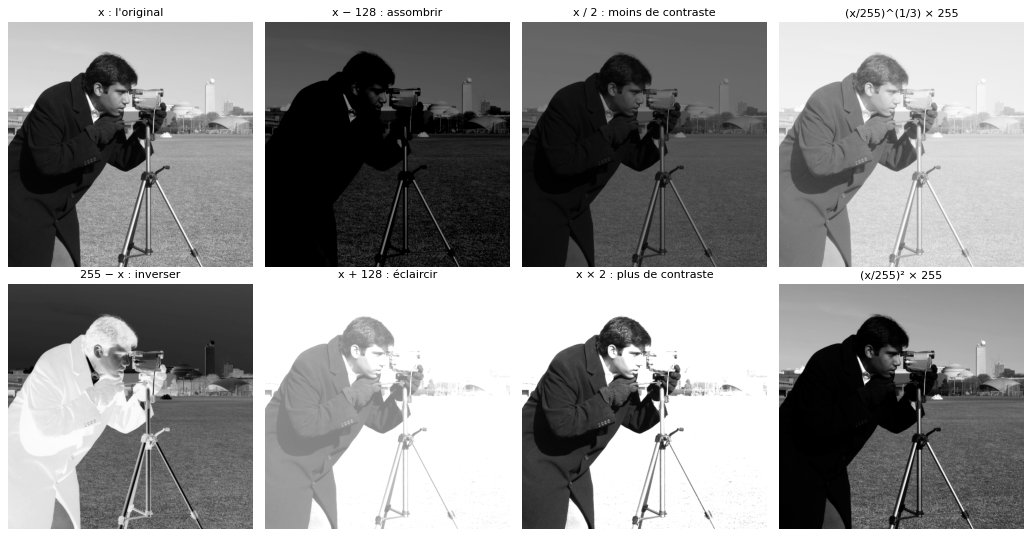

In [ ]:
x = camera.astype(np.float64)
point_operations = {
    "x : l'original": x,
    "x - 128 : assombrir": x - 128,
    "x / 2 : moins de contraste": x / 2,
    "(x/255)^(1/3) * 255": (x / 255) ** (1 / 3) * 255,
    "255 - x : inverser": 255 - x,
    "x + 128 : éclaircir": x + 128,
    "x * 2 : plus de contraste": x * 2,
    "(x/255)² * 255": (x / 255) ** 2 * 255,
}

fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for ax, (title, result) in zip(axes.ravel(), point_operations.items()):
    ax.imshow(np.clip(result, 0, 255).astype(np.uint8), cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

Puisque le nouveau pixel ne dépend que de l’ancien, chaque opération est une simple **courbe** : une valeur d’entrée de 0 à 255 donne une valeur de sortie. La transformation logarithmique de l’ancien labo, $255 \cdot \log(1 + x) / \log(256)$, en est une autre.

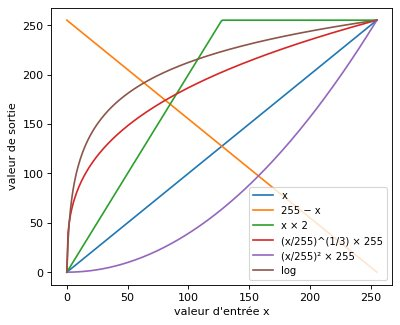

In [14]:
levels = np.arange(256, dtype=np.float64)
curves = {
    "x": levels,
    "255 − x": 255 - levels,
    "x × 2": levels * 2,
    "(x/255)^(1/3) × 255": (levels / 255) ** (1 / 3) * 255,
    "(x/255)² × 255": (levels / 255) ** 2 * 255,
    "log": 255 * np.log1p(levels) / np.log(256),
}
plt.figure(figsize=(5.5, 4.5))
for name, curve in curves.items():
    plt.plot(levels, np.clip(curve, 0, 255), label=name)
plt.xlabel("valeur d'entrée x")
plt.ylabel("valeur de sortie")
plt.legend(fontsize=9)
plt.show()

Il n’y a que 256 entrées possibles. Plutôt que de refaire le calcul pour chacun des 262 144 pixels, on peut le faire une fois pour les 256 valeurs, puis aller chercher le résultat dans cette **table de correspondance** (*lookup table*). C’est ce que fait `cv2.LUT`.

In [15]:
table = np.clip((levels / 255) ** 2 * 255, 0, 255).astype(np.uint8)  # 256 valeurs, calculées une fois
with_table = cv2.LUT(camera, table)
direct = np.clip((x / 255) ** 2 * 255, 0, 255).astype(np.uint8)
print("Même image :", np.array_equal(with_table, direct))

Même image : True


### L’histogramme

L’**histogramme** compte combien de pixels prennent chaque valeur. Il résume le contraste d’une image en un coup d’œil. L’image `moon` est terne : la plupart de ses pixels sont gris moyen.

Deux façons d’améliorer son contraste :

- l’**étirement du contraste** est une droite : il envoie une valeur basse vers 0 et une valeur haute vers 255. Attention : `moon` contient quelques pixels à 0 et à 255, donc étirer du minimum au maximum ne change rien. On étire plutôt entre les centiles 1 et 99;
- l’**égalisation d’histogramme** (`cv2.equalizeHist`) choisit la courbe qui étale les valeurs le plus uniformément possible.

moon : minimum 0, maximum 255, mais 98 % des pixels entre 58 et 141


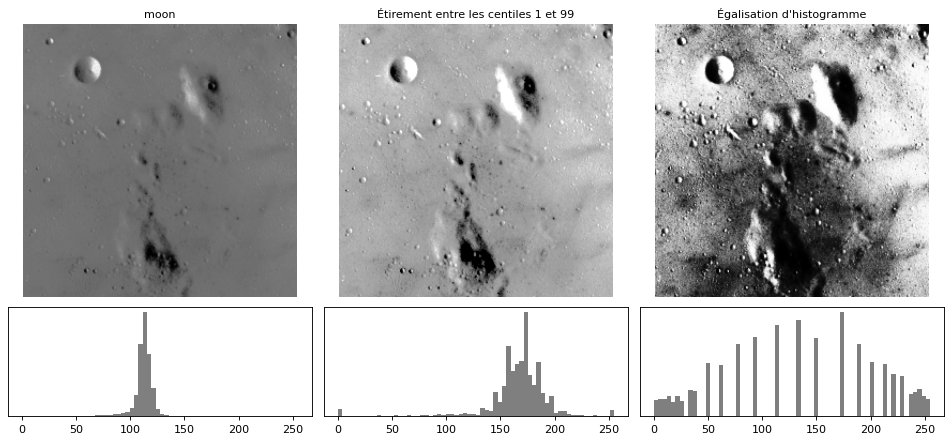

In [16]:
def show_with_histograms(images, titles):
    fig, axes = plt.subplots(2, len(images), figsize=(4 * len(images), 5.6), gridspec_kw={"height_ratios": [3, 1.2]})
    for column, (image, title) in enumerate(zip(images, titles)):
        axes[0, column].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[0, column].set_title(title, fontsize=10)
        axes[0, column].axis("off")
        axes[1, column].hist(image.ravel(), bins=64, range=(0, 255), color="tab:gray")
        axes[1, column].set_yticks([])
    plt.tight_layout()
    plt.show()


moon = data.moon()
low, high = np.percentile(moon, [1, 99])
print(f"moon : minimum {moon.min()}, maximum {moon.max()}, mais 98 % des pixels entre {low:.0f} et {high:.0f}")

stretched = np.clip((moon - low) / (high - low) * 255, 0, 255).astype(np.uint8)
equalized = cv2.equalizeHist(moon)
show_with_histograms([moon, stretched, equalized], ["moon", "Étirement entre les centiles 1 et 99", "Égalisation d'histogramme"])

La **correction gamma** applique la courbe $255 \cdot (x / 255)^\gamma$. Avec $\gamma < 1$, les zones sombres s’éclaircissent; avec $\gamma > 1$, elles s’assombrissent. Déplacez le curseur et regardez l’histogramme se déformer.

In [17]:
@interact(gamma=FloatSlider(value=0.5, min=0.2, max=3.0, step=0.1, continuous_update=False))
def gamma_correction(gamma):
    corrected = np.clip(255 * (moon / 255) ** gamma, 0, 255).astype(np.uint8)
    show_with_histograms([moon, corrected], ["moon", f"gamma = {gamma:.1f}"])

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='gamma', max=3.0, min=0.2), …

### Le seuillage

Le **seuillage** est une opération ponctuelle non linéaire : chaque pixel devient blanc s’il dépasse un seuil, noir sinon. On obtient une image binaire, un premier découpage de l’image en objets et en fond.

Choisir le seuil à la main fonctionne mal d’une image à l’autre. La méthode d’**Otsu** le choisit à partir de l’histogramme : elle cherche le seuil qui sépare le mieux les pixels en deux groupes homogènes.

Seuil choisi par Otsu : 107.0


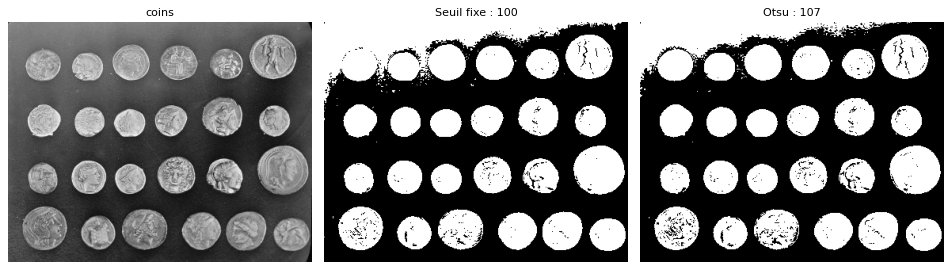

In [18]:
coins = data.coins()
_, fixed = cv2.threshold(coins, 100, 255, cv2.THRESH_BINARY)  # 255 si le pixel dépasse 100, 0 sinon
otsu_value, otsu = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # le seuil 0 est ignoré

print("Seuil choisi par Otsu :", otsu_value)
show(coins, fixed, otsu, titles=["coins", "Seuil fixe : 100", f"Otsu : {otsu_value:.0f}"], size=4)

Les deux masques ratent le coin supérieur gauche : l’éclairage n’est pas uniforme, et le fond y est aussi clair que certaines pièces. **Un seul seuil pour toute l’image ne suffit pas.**

Le problème est encore plus net sur cette page scannée, plus sombre en bas à gauche. Le **seuillage adaptatif** compare chaque pixel à la moyenne de son voisinage plutôt qu’à un seuil unique. C’est déjà une opération sur les voisins, comme les filtres de la section C.

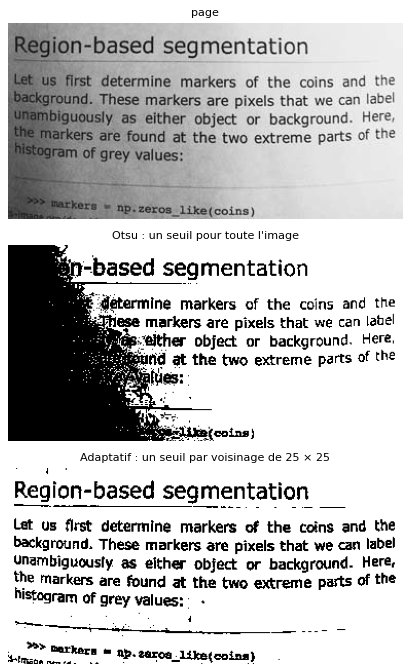

In [19]:
page = data.page()
_, page_otsu = cv2.threshold(page, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
page_adaptive = cv2.adaptiveThreshold(page, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 25, 10)

fig, axes = plt.subplots(3, 1, figsize=(8, 8.5))
for ax, image, title in zip(axes, [page, page_otsu, page_adaptive],
                            ["page", "Otsu : un seuil pour toute l'image", "Adaptatif : un seuil par voisinage de 25 × 25"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Compter les pièces

Avec ces outils et un peu de **morphologie mathématique**, on peut compter les pièces de `coins`. La morphologie travaille sur la forme des objets, avec un petit motif appelé *élément structurant* (ici un disque) :

- l’**érosion** garde un pixel blanc seulement si tout le disque autour de lui est blanc : les objets rétrécissent;
- la **dilatation** rend un pixel blanc si au moins un pixel du disque l’est : les objets grossissent;
- l’**ouverture** (érosion puis dilatation) efface les petits points blancs isolés;
- la **fermeture** (dilatation puis érosion) bouche les petits trous noirs.

Le plan :

1. **Retirer le fond.** L’ouverture avec un disque plus grand que les pièces efface les pièces et ne garde que le fond, avec son éclairage inégal. On le soustrait de l’image : c’est la transformation *top-hat*.
2. **Seuiller** avec Otsu.
3. **Nettoyer** le masque avec une ouverture et une fermeture.
4. **Compter** les composantes connexes : les groupes de pixels blancs qui se touchent.

25 composantes, dont 24 de plus de 100 pixels : 24 pièces


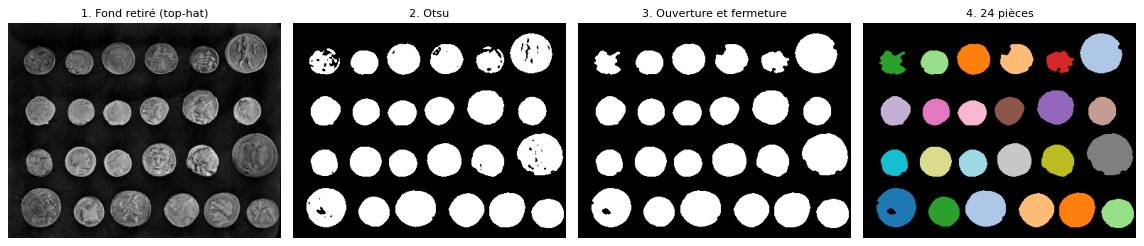

In [20]:
def disk(size):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))


background_removed = cv2.morphologyEx(coins, cv2.MORPH_TOPHAT, disk(61))   # image − ouverture(image)
_, coin_mask = cv2.threshold(cv2.GaussianBlur(background_removed, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
opened = cv2.morphologyEx(coin_mask, cv2.MORPH_OPEN, disk(5))              # retire les petits points blancs
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, disk(5))               # bouche les petits trous

n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cleaned)
areas = stats[1:, cv2.CC_STAT_AREA]  # l'étiquette 0 est le fond
n_coins = (areas > 100).sum()
print(f"{n_labels - 1} composantes, dont {n_coins} de plus de 100 pixels : {n_coins} pièces")

colored = (plt.cm.tab20(labels % 20)[..., :3] * 255).astype(np.uint8)
colored[labels == 0] = 0
show(background_removed, coin_mask, cleaned, colored,
     titles=["1. Fond retiré (top-hat)", "2. Otsu", "3. Ouverture et fermeture", f"4. {n_coins} pièces"], size=3.6)

Il y a bien 24 pièces sur l’image. Remarquez que le seuil vient en deuxième position : il a fallu **préparer les données** avant de pouvoir seuiller.

## C. Filtrer : la convolution

Un **filtre** calcule chaque nouveau pixel à partir d’un voisinage de l’image d’origine. Il sert à deux choses :

- **extraire de l’information** : des caractéristiques comme les contours ou les coins;
- **modifier l’image** : la débruiter, la rendre plus nette.

### La moyenne mobile, à la main

Le filtre le plus simple remplace chaque pixel par la **moyenne de ses 9 voisins** (lui compris), dans une fenêtre de 3 × 3. Reprenons la petite image $F$ des diapositives : un carré de 90 avec un trou, et un pixel isolé en bas.

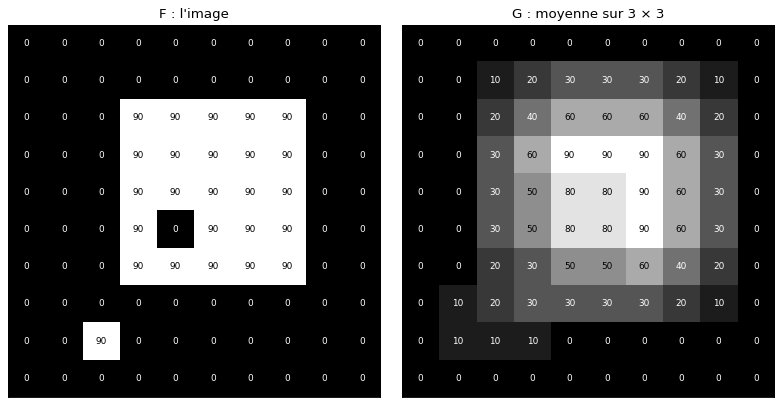

In [21]:
f_grid = np.zeros((10, 10))
f_grid[2:7, 3:8] = 90  # un carré clair
f_grid[5, 4] = 0       # un trou dans le carré
f_grid[8, 2] = 90      # un pixel isolé

g_grid = np.zeros_like(f_grid)
for n in range(1, 9):          # on laisse de côté la bordure
    for m in range(1, 9):
        g_grid[n, m] = f_grid[n - 1 : n + 2, m - 1 : m + 2].sum() / 9


def show_grids(*grids, titles):
    fig, axes = plt.subplots(1, len(grids), figsize=(5 * len(grids), 5))
    for ax, grid, title in zip(axes, grids, titles):
        ax.imshow(grid, cmap="gray", vmin=0, vmax=90)
        for (n, m), value in np.ndenumerate(grid):
            ax.text(m, n, f"{value:.0f}", ha="center", va="center", fontsize=8, color="black" if value > 45 else "white")
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.show()


show_grids(f_grid, g_grid, titles=["F : l'image", "G : moyenne sur 3 × 3"])

La moyenne adoucit les bords du carré, comble presque le trou et étale le pixel isolé : c’est un **flou**.

Écrivons le calcul en général. Chaque voisin reçoit un poids $h[k, l]$, et la grille $h$ s’appelle le **noyau** (*kernel*) du filtre :

$$G[n, m] = \sum_{k=-1}^{1} \sum_{l=-1}^{1} h[k, l] \, F[n + k, m + l]$$

Pour la moyenne, les 9 poids valent $1/9$. `cv2.filter2D` applique n’importe quel noyau.

In [22]:
box = np.ones((3, 3)) / 9  # le noyau de la moyenne
g_opencv = cv2.filter2D(f_grid, -1, box)  # -1 : même type que l'entrée
print("Même résultat à l'intérieur :", np.allclose(g_opencv[1:-1, 1:-1], g_grid[1:-1, 1:-1]))

Même résultat à l'intérieur : True


### Une galerie de noyaux

Changer le noyau change le filtre. Voici les noyaux classiques du cours et de l’ancien labo, appliqués à un détail de `camera`. Le petit carré en bas à gauche de chaque image montre le noyau : rouge pour les poids positifs, bleu pour les négatifs.

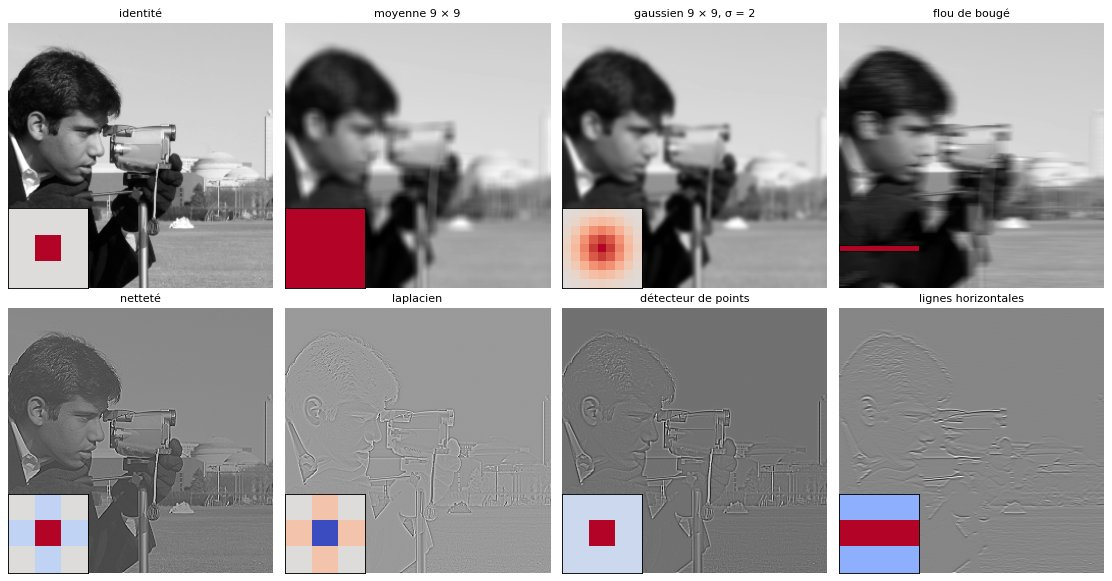

In [ ]:
KERNELS = {
    "identité": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]),
    "moyenne 9 * 9": np.ones((9, 9)) / 81,
    "gaussien 9 * 9, σ = 2": cv2.getGaussianKernel(9, 2) @ cv2.getGaussianKernel(9, 2).T,
    "flou de bougé": np.ones((1, 15)) / 15,
    "netteté": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "laplacien": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]),
    "détecteur de points": np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]),
    "lignes horizontales": np.array([[-1, -1, -1], [2, 2, 2], [-1, -1, -1]]),
}

detail = camera[40:300, 160:420].astype(np.float64)
fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for ax, (name, kernel) in zip(axes.ravel(), KERNELS.items()):
    ax.imshow(cv2.filter2D(detail, -1, kernel.astype(np.float64)), cmap="gray")
    ax.set_title(name, fontsize=10)
    ax.axis("off")
    inset = ax.inset_axes([0.0, 0.0, 0.3, 0.3])
    limit = np.abs(kernel).max()
    inset.imshow(kernel, cmap="coolwarm", vmin=-limit, vmax=limit)
    inset.set_xticks([])
    inset.set_yticks([])
plt.tight_layout()
plt.show()

Les noyaux dont les poids sont **tous positifs** (moyenne, gaussien, bougé) rendent l’image floue. Ceux dont les poids **s’annulent** (laplacien, détecteurs) répondent seulement là où l’intensité change : partout ailleurs, le résultat est nul. Ce sont déjà des détecteurs de caractéristiques. Nous retrouverons plusieurs de ces noyaux à la section F.

### Rendre plus net

Le noyau de netteté se comprend en deux temps. On retire à l’image sa version floue : il reste les **détails**. Puis on ajoute ces détails à l’image d’origine.

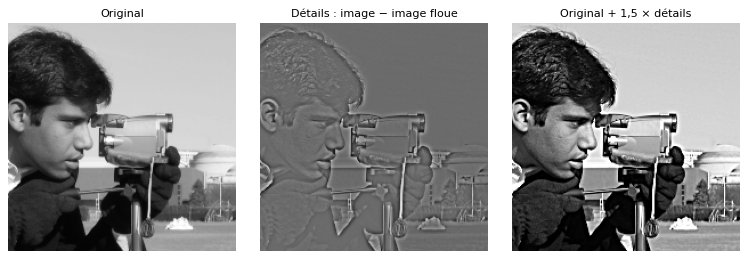

In [24]:
blurred = cv2.GaussianBlur(camera, (9, 9), 2).astype(np.float64)
details = camera - blurred                       # ce que le flou a fait disparaître
sharpened = np.clip(camera + 1.5 * details, 0, 255).astype(np.uint8)

zoom = (slice(60, 260), slice(180, 380))
show(camera[zoom], details[zoom], sharpened[zoom], titles=["Original", "Détails : image − image floue", "Original + 1,5 × détails"])

### Retirer le bruit

Les capteurs ajoutent du bruit aux images. Comparons trois filtres sur deux bruits différents :

- un **bruit gaussien** : chaque pixel est un peu décalé au hasard;
- un bruit **poivre et sel** : quelques pixels deviennent complètement noirs ou blancs.

Le filtre **médian** remplace chaque pixel par la médiane de son voisinage. Ce n’est **pas** une convolution : trier des valeurs n’est pas une somme pondérée.

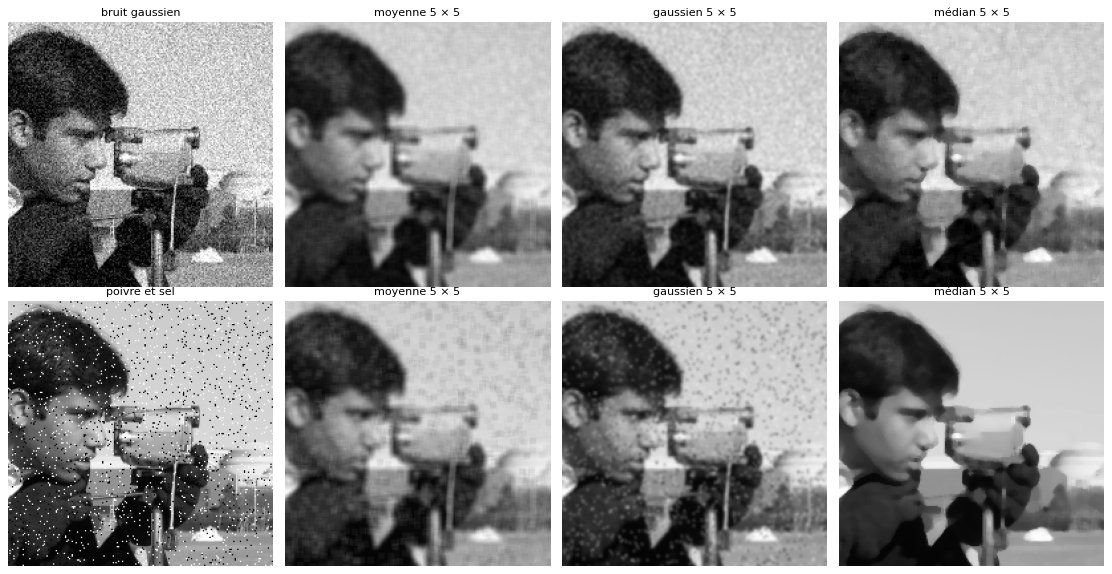

In [25]:
rng = np.random.default_rng(0)
gaussian_noise = np.clip(camera + rng.normal(0, 25, camera.shape), 0, 255).astype(np.uint8)
salt_and_pepper = camera.copy()
spots = rng.random(camera.shape)
salt_and_pepper[spots < 0.03] = 0
salt_and_pepper[spots > 0.97] = 255

fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
for row_axes, (noise_name, noisy) in zip(axes, [("bruit gaussien", gaussian_noise), ("poivre et sel", salt_and_pepper)]):
    results = {
        noise_name: noisy,
        "moyenne 5 × 5": cv2.blur(noisy, (5, 5)),
        "gaussien 5 × 5": cv2.GaussianBlur(noisy, (5, 5), 0),
        "médian 5 × 5": cv2.medianBlur(noisy, 5),
    }
    for ax, (title, image) in zip(row_axes, results.items()):
        ax.imshow(image[zoom], cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

Sur le bruit gaussien, les trois filtres se valent à peu près. Sur le poivre et sel, la moyenne et le gaussien étalent chaque point en une tache grise, tandis que le **médian** les fait disparaître : un point isolé n’est jamais la médiane de son voisinage.

### Convolution ou corrélation ?

La formule de $G$ plus haut est en fait une **corrélation** : le poids $h[k, l]$ multiplie le voisin $F[n + k, m + l]$. La **convolution** des mathématiques utilise $F[n - k, m - l]$, ce qui revient à **retourner le noyau** :

$$(F * h)[n, m] = \sum_{k, l} h[k, l] \, F[n - k, m - l]$$

`cv2.filter2D` calcule une corrélation. Pour un noyau symétrique, comme la moyenne ou le gaussien, les deux donnent le même résultat. Pour un noyau asymétrique, non. Prenons un noyau qui ne contient qu’un seul 1, à son extrémité droite.

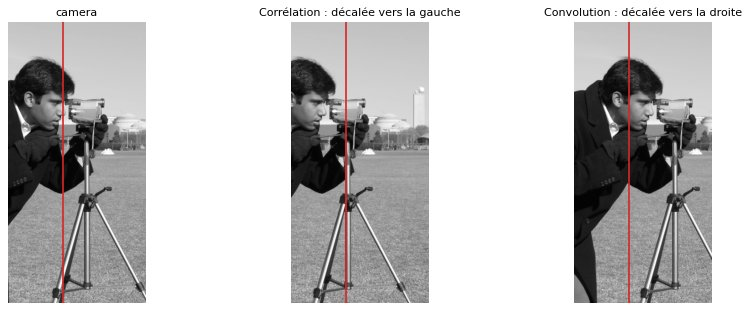

In [26]:
shift_kernel = np.zeros((1, 81))
shift_kernel[0, -1] = 1  # un seul 1, tout à droite du noyau

correlation = cv2.filter2D(camera, -1, shift_kernel)          # ce que calcule filter2D
convolution = cv2.filter2D(camera, -1, shift_kernel[:, ::-1])  # noyau retourné : la convolution

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, image, title in zip(axes, [camera, correlation, convolution],
                            ["camera", "Corrélation : décalée vers la gauche", "Convolution : décalée vers la droite"]):
    ax.imshow(image[:, 150:400], cmap="gray", vmin=0, vmax=255)
    ax.axvline(250 - 150, color="tab:red")  # la même colonne dans les trois images
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

La corrélation va chercher le pixel situé 40 colonnes **à droite** : l’image se décale vers la gauche. La convolution fait l’inverse. Retenez surtout que la plupart des bibliothèques (OpenCV, mais aussi PyTorch à la section F) calculent une corrélation, et l’appellent souvent convolution.

### Les filtres séparables

Certains noyaux 2D sont le produit d’une **colonne** par une **ligne**. Filtrer avec le noyau 2D revient alors à filtrer deux fois en 1D : d’abord les colonnes, puis les lignes.

In [27]:
column = np.array([[1], [2], [1]]) / 4
row_1d = np.array([[1, 2, 1]]) / 4
print("colonne × ligne =\n", column @ row_1d * 16, "/ 16  : le noyau gaussien 3 × 3")

one_pass = cv2.filter2D(camera.astype(np.float64), -1, column @ row_1d)
two_passes = cv2.sepFilter2D(camera.astype(np.float64), -1, row_1d.ravel(), column.ravel())
print("\nMême résultat :", np.allclose(one_pass, two_passes))

colonne × ligne =
 [[1. 2. 1.]
 [2. 4. 2.]
 [1. 2. 1.]] / 16  : le noyau gaussien 3 × 3

Même résultat : True


Avec un noyau de $k \times k$, il faut $k^2$ multiplications par pixel en une passe, contre $2k$ en deux passes. Pour $k = 31$, c’est 961 contre 62. Les noyaux de la moyenne, du gaussien et de Sobel (section D) sont tous séparables.

### L’équivariance par translation

Une propriété essentielle : **décaler l’image puis la filtrer donne le même résultat que la filtrer puis décaler le résultat**. On dit que le filtre est **équivariant** par translation. Un même motif est donc détecté de la même façon, où qu’il se trouve dans l’image.

Vérifions-le. La fonction `shift_image` décale une image en complétant avec des zéros; elle utilise `cv2.warpAffine`, que nous verrons à la section E.

In [28]:
def shift_image(image, dy, dx):
    """Décale l'image de dy lignes vers le bas et de dx colonnes vers la droite, en complétant avec des zéros."""
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(image, M, (image.shape[1], image.shape[0]))


def blur(image):
    return cv2.GaussianBlur(image, (9, 9), 2)


dy, dx = 15, 40
shift_then_blur = blur(shift_image(camera, dy, dx)).astype(int)
blur_then_shift = shift_image(blur(camera), dy, dx).astype(int)
inside = (slice(dy + 10, -10), slice(dx + 10, -10))  # loin des bords, où les zéros ajoutés interviennent
print("Plus grande différence loin des bords :", np.abs(shift_then_blur - blur_then_shift)[inside].max())

Plus grande différence loin des bords : 0


Aucune différence. Dans le vocabulaire du cours, $f$ est **équivariante** si $f(t(x)) = t(f(x))$ pour toute translation $t$, et **invariante** si $f(t(x)) = f(x)$. Un filtre est équivariant : quand l’image bouge, sa sortie bouge avec elle. C’est cette propriété que les réseaux convolutifs exploitent à la section F.

### À vous : écrire la convolution

Complétez `convolve2d` avec NumPy. Ajoutez des zéros autour de l’image (*padding*), retournez le noyau, puis faites la somme pondérée pour chaque pixel. Deux boucles suffisent. La cellule suivante compare votre fonction à OpenCV.

In [29]:
def convolve2d(image, kernel):
    # image : (H, W), kernel : (k, k) avec k impair. Bordure : des zéros.
    # Votre code ici : remplacez pass, puis renvoyez un tableau de réels de forme (H, W).
    pass

In [30]:
rng = np.random.default_rng(0)
test_image = rng.integers(0, 256, size=(12, 15)).astype(np.float64)
symmetric = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64)
asymmetric = np.array([[1, 2, 0], [0, -1, 0], [0, 0, 3]], dtype=np.float64)


def opencv_correlation(image, kernel):
    return cv2.filter2D(image, -1, kernel, borderType=cv2.BORDER_CONSTANT)  # bordure de zéros


result = convolve2d(test_image, symmetric)
if result is None:
    print("La fonction n'est pas encore complétée.")
else:
    assert result.shape == test_image.shape, "La sortie doit avoir la même forme que l'image."
    assert np.allclose(result, opencv_correlation(test_image, symmetric)), "Le noyau symétrique ne donne pas le bon résultat."
    result = convolve2d(test_image, asymmetric)
    if np.allclose(result, opencv_correlation(test_image, asymmetric)):
        print("Presque : vous avez écrit une corrélation. Retournez le noyau.")
    else:
        assert np.allclose(result, opencv_correlation(test_image, asymmetric[::-1, ::-1])), "Le noyau asymétrique ne donne pas le bon résultat."
        print("Bravo ! Votre convolution donne le même résultat qu'OpenCV avec le noyau retourné.")

La fonction n'est pas encore complétée.


<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
def convolve2d(image, kernel):
    k = kernel.shape[0] // 2
    flipped = kernel[::-1, ::-1]                 # la convolution retourne le noyau
    padded = np.pad(image.astype(np.float64), k)  # k zéros de chaque côté
    output = np.zeros(image.shape)
    for n in range(image.shape[0]):
        for m in range(image.shape[1]):
            window = padded[n : n + 2 * k + 1, m : m + 2 * k + 1]  # le voisinage centré sur (n, m)
            output[n, m] = (window * flipped).sum()
    return output
```

Avec le padding, le pixel $(n, m)$ de l’image se trouve en $(n + k, m + k)$ dans `padded`. Son voisinage commence donc en $(n, m)$.

Ces deux boucles en Python sont lentes : environ une seconde pour `camera`, contre une milliseconde pour OpenCV, écrit en C++. C’est pour cette raison qu’on utilise les bibliothèques.

Si vous avez essayé cette réponse, réexécutez la cellule de vérification.

</details>

## D. Les contours, une première caractéristique

Un **contour** est un endroit où l’intensité change brusquement. Ces changements viennent souvent d’une frontière entre objets, d’un changement de matière ou d’une ombre. Le cours donne deux raisons pour lesquelles ils sont utiles :

1. ils portent l’essentiel de la **forme** des objets;
2. ils sont bien plus **compacts** que l’ensemble des pixels.

### Le long d’une ligne

Reprenons la ligne y = 200 de la section A. Un changement brusque d’intensité est un grand écart entre deux pixels voisins, donc une grande **dérivée**. Avec des pixels, la dérivée se calcule comme une différence : $f(x + 1) - f(x)$.

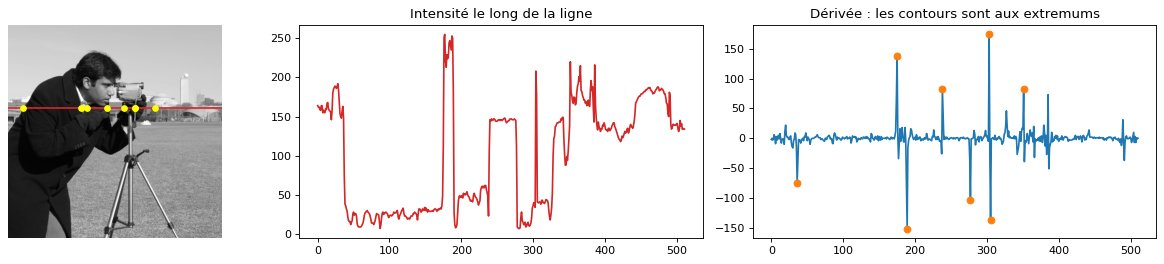

In [31]:
profile = camera[row].astype(np.float64)
derivative = np.diff(profile)                          # f(x + 1) − f(x)
strongest = np.argsort(np.abs(derivative))[-8:]        # les 8 plus fortes variations

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})
axes[0].imshow(camera, cmap="gray", vmin=0, vmax=255)
axes[0].axhline(row, color="tab:red")
axes[0].plot(strongest, [row] * len(strongest), "o", color="yellow", markersize=5)
axes[0].axis("off")
axes[1].plot(profile, color="tab:red")
axes[1].set_title("Intensité le long de la ligne")
axes[2].plot(derivative, color="tab:blue")
axes[2].plot(strongest, derivative[strongest], "o", color="tab:orange")
axes[2].set_title("Dérivée : les contours sont aux extremums")
plt.tight_layout()
plt.show()

Les points jaunes marquent les huit plus fortes variations : chacun tombe sur le bord d’un objet que la ligne traverse.

### Le problème du bruit

Sur un vrai signal, le bruit gâche tout. Prenons un saut de 50 à 150 avec un peu de bruit. Chaque petite variation aléatoire produit une dérivée aussi forte que le saut lui-même.

La solution du cours : **lisser d’abord**, avec un noyau gaussien $g$, **puis dériver**. Le contour est alors le pic de $\frac{d}{dx}(f * g)$.

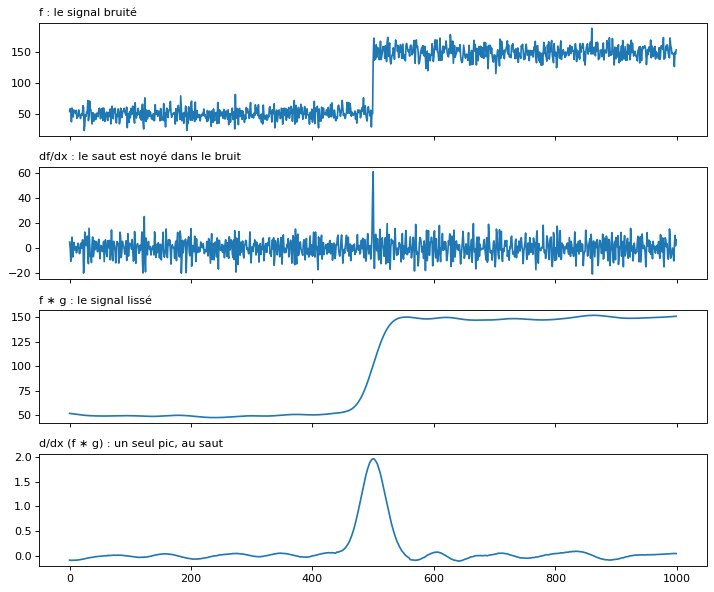

In [32]:
def smooth_1d(signal, kernel):
    padded = np.pad(signal, len(kernel) // 2, mode="edge")  # prolonge les extrémités pour éviter les effets de bord
    return np.convolve(padded, kernel, mode="valid")


rng = np.random.default_rng(1)
positions = np.arange(1000)
f = np.where(positions < 500, 50.0, 150.0) + rng.normal(0, 10, positions.size)  # un saut, avec du bruit
g = cv2.getGaussianKernel(121, 20).ravel()                                       # noyau gaussien, σ = 20
smoothed = smooth_1d(f, g)

fig, axes = plt.subplots(4, 1, figsize=(9, 7.5), sharex=True)
panels = [(f, "f : le signal bruité"), (np.gradient(f), "df/dx : le saut est noyé dans le bruit"),
          (smoothed, "f ∗ g : le signal lissé"), (np.gradient(smoothed), "d/dx (f ∗ g) : un seul pic, au saut")]
for ax, (signal, title) in zip(axes, panels):
    ax.plot(positions, signal)
    ax.set_title(title, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

Encore mieux : la dérivée d’une convolution est la convolution par la dérivée du noyau, $\frac{d}{dx}(f * g) = f * \frac{dg}{dx}$. **Un seul noyau, la dérivée de la gaussienne, lisse et dérive en une passe.**

In [33]:
derivative_kernel = np.convolve(g, [0.5, 0, -0.5])   # la dérivée du noyau : (g[x + 1] - g[x - 1]) / 2, comme np.gradient
in_one_pass = smooth_1d(f, derivative_kernel)        # un seul noyau : la dérivée de la gaussienne
in_two_passes = np.gradient(smoothed)                # lisser, puis dériver
print("Même résultat loin des bords :", np.allclose(in_one_pass[100:-100], in_two_passes[100:-100]))
print("Le contour est trouvé en x =", np.argmax(np.abs(in_one_pass)))

Même résultat loin des bords : True
Le contour est trouvé en x = 500


### Sobel : la même idée en 2D

Le filtre de **Sobel** applique cette recette avec un petit noyau de 3 × 3 : il **lisse** dans une direction ($[1, 2, 1]$) et **dérive** dans l’autre ($[-1, 0, 1]$). C’est un filtre séparable, comme ceux de la section C.

- $g_x$, la dérivée selon x, répond aux contours verticaux;
- $g_y$, la dérivée selon y, répond aux contours horizontaux;
- la **norme du gradient** $\sqrt{g_x^2 + g_y^2}$ mesure la force du contour, quelle que soit sa direction.

Noyau de Sobel en x :
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]


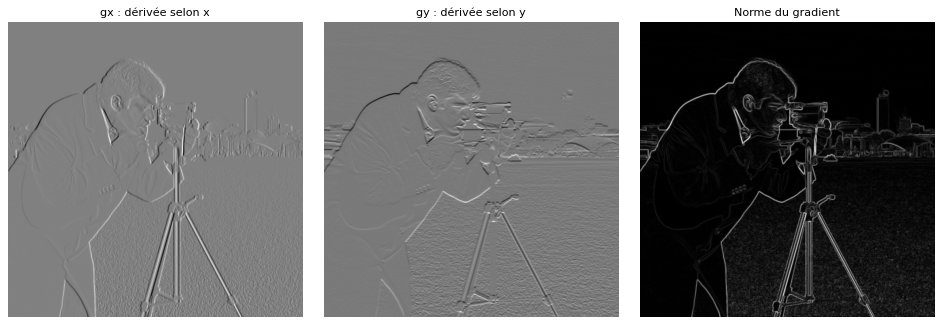

In [34]:
SOBEL_X = np.outer([1, 2, 1], [-1, 0, 1])  # lisser verticalement × dériver horizontalement
print("Noyau de Sobel en x :\n", SOBEL_X)

gx = cv2.Sobel(camera, cv2.CV_64F, 1, 0, ksize=3)  # dérivée selon x, en réels
gy = cv2.Sobel(camera, cv2.CV_64F, 0, 1, ksize=3)  # dérivée selon y
magnitude = np.hypot(gx, gy)                       # norme du gradient
show(gx, gy, magnitude, titles=["gx : dérivée selon x", "gy : dérivée selon y", "Norme du gradient"], size=4)

**Piège :** une dérivée peut être négative (du clair vers le sombre). Avec le type de sortie `-1`, c’est-à-dire `uint8` comme l’image, OpenCV ramène toutes les valeurs négatives à 0, et **la moitié des contours disparaît**. Demandez toujours une sortie en réels, `cv2.CV_64F`.

Plus petite valeur en CV_64F : -860 | en uint8 : 0


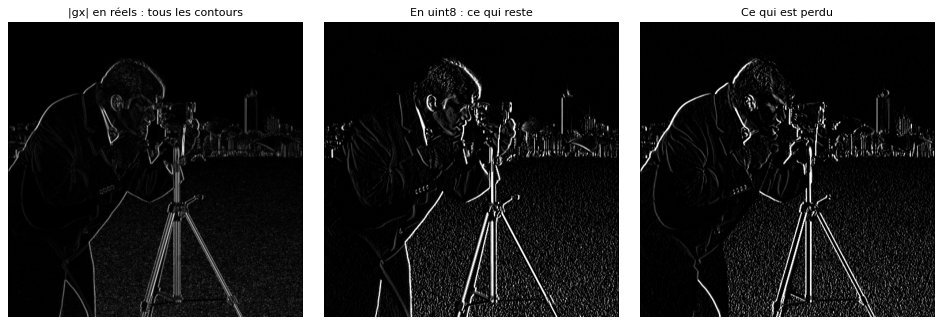

In [35]:
gx_uint8 = cv2.Sobel(camera, -1, 1, 0, ksize=3)  # -1 : même type que l'entrée, donc uint8
print(f"Plus petite valeur en CV_64F : {gx.min():.0f} | en uint8 : {gx_uint8.min()}")
lost = np.clip(-gx, 0, 255)  # les dérivées négatives, que le uint8 met à 0
show(np.abs(gx), gx_uint8, lost, titles=["|gx| en réels : tous les contours", "En uint8 : ce qui reste", "Ce qui est perdu"], size=4)

Le gradient a aussi une **orientation** : l’angle $\arctan(g_y / g_x)$ indique dans quelle direction l’intensité augmente. Affichons-la avec l’espace HSV de la section A : la teinte code l’orientation, la luminosité code la norme.

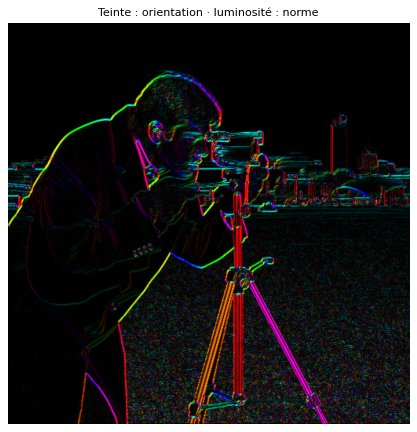

In [36]:
angle = np.degrees(np.arctan2(gy, gx)) % 180                  # orientation du contour, de 0 à 180°
brightness = np.clip(magnitude / np.percentile(magnitude, 99) * 255, 0, 255)
hsv_gradient = np.stack([angle, np.full_like(angle, 255), brightness], axis=-1).astype(np.uint8)  # H va de 0 à 179
show(cv2.cvtColor(hsv_gradient, cv2.COLOR_HSV2RGB), titles=["Teinte : orientation · luminosité : norme"], size=5.5)

Les bords verticaux du trépied ont une couleur, les bords horizontaux une autre. Ces histogrammes d’orientations de gradient sont à la base des caractéristiques HOG, très utilisées avant les réseaux convolutifs.

### Canny

La **norme du gradient** donne des contours épais et bruités. Le détecteur de **Canny** (1986) en tire des contours fins, en quatre étapes :

1. lisser avec un gaussien;
2. calculer le gradient (Sobel);
3. ne garder que les maxima locaux du gradient dans sa direction : les contours deviennent fins d’un pixel;
4. appliquer deux seuils : au-dessus du seuil haut, c’est un contour; entre les deux, seulement s’il touche un contour fort.

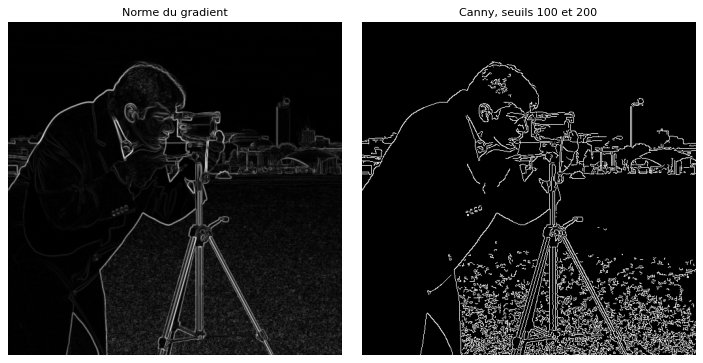

In [37]:
show(magnitude, cv2.Canny(camera, 100, 200), titles=["Norme du gradient", "Canny, seuils 100 et 200"], size=4.5)

Jouez avec les deux seuils : un seuil bas trop faible laisse passer le gazon, un seuil haut trop fort efface le visage.

In [38]:
@interact(low=IntSlider(value=100, min=0, max=300, step=10, continuous_update=False),
          high=IntSlider(value=200, min=0, max=500, step=10, continuous_update=False))
def canny_thresholds(low, high):
    show(cv2.Canny(camera, low, high), titles=[f"Canny, seuils {low} et {high}"], size=5)

interactive(children=(IntSlider(value=100, continuous_update=False, description='low', max=300, step=10), IntS…

## E. Déformer et augmenter

Le cours distingue deux façons de transformer une image $F$ :

- **filtrer** change les **valeurs** des pixels : $G(x) = h(F(x))$. C’est ce que nous avons fait jusqu’ici;
- **déformer** change leur **position** : $G(x) = F(h(x))$. Les valeurs ne changent pas, elles se déplacent.

### Redimensionner

Agrandir une image oblige à inventer des pixels. La méthode d’**interpolation** décide comment.

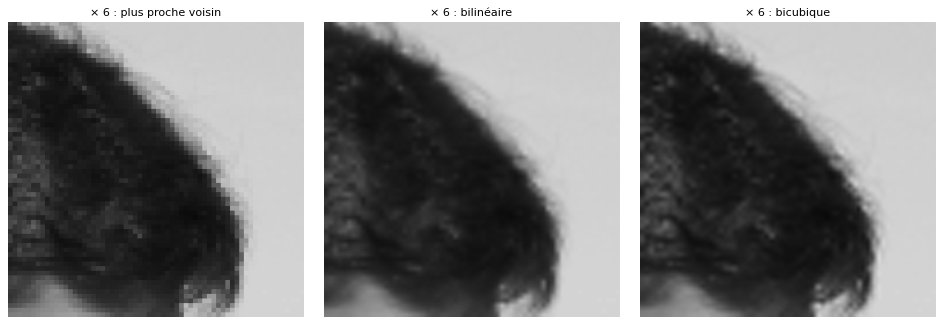

In [39]:
face = camera[70:134, 220:284]  # 64 × 64 pixels
methods = {"plus proche voisin": cv2.INTER_NEAREST, "bilinéaire": cv2.INTER_LINEAR, "bicubique": cv2.INTER_CUBIC}
enlarged = [cv2.resize(face, None, fx=6, fy=6, interpolation=method) for method in methods.values()]
show(*enlarged, titles=[f"× 6 : {name}" for name in methods], size=4)

Le plus proche voisin recopie les pixels et fait des escaliers; le bilinéaire et le bicubique les mélangent et donnent un résultat plus doux. Pour **réduire** une image, préférez `cv2.INTER_AREA`, qui fait la moyenne des pixels regroupés.

### Tourner

Une rotation, comme un décalage ou un changement d’échelle, est une **transformation affine** : la nouvelle position est $M \cdot (x, y, 1)$, avec $M$ une matrice de 2 × 3. `cv2.getRotationMatrix2D` la construit, et `cv2.warpAffine` l’applique.

Matrice affine :
 [[  0.87   0.5  -93.7 ]
 [ -0.5    0.87 162.3 ]]


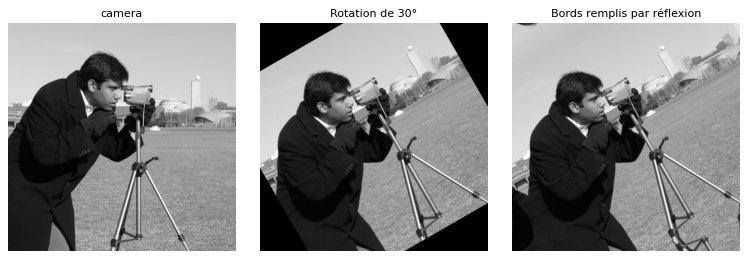

In [40]:
height, width = camera.shape
center = (width / 2, height / 2)                     # (x, y), encore une fois
M = cv2.getRotationMatrix2D(center, 30, 1.0)         # 30° dans le sens antihoraire, sans changer l'échelle
print("Matrice affine :\n", M.round(2))

rotated = cv2.warpAffine(camera, M, (width, height))
rotated_reflect = cv2.warpAffine(camera, M, (width, height), borderMode=cv2.BORDER_REFLECT)
show(camera, rotated, rotated_reflect, titles=["camera", "Rotation de 30°", "Bords remplis par réflexion"])

Les coins noirs sont des pixels qui n’existaient pas dans l’image d’origine. `borderMode` choisit comment les remplir.

### Redresser une perspective

Une photo prise de biais ne conserve pas les parallèles : il faut une transformation de **perspective** (une matrice de 3 × 3). Il suffit de quatre points et de leur position voulue pour la calculer. Les applications qui « scannent » un document avec un téléphone font exactement cela. Simulons une photo de biais, puis redressons-la.

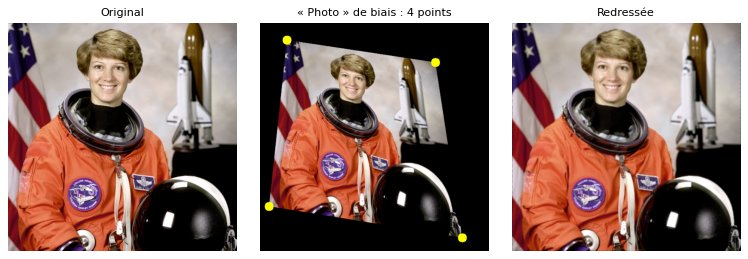

In [41]:
h, w = astronaut.shape[:2]
corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]])                          # (x, y) des 4 coins
on_photo = np.float32([[60, 40], [w - 120, 90], [w - 60, h - 30], [20, h - 100]])  # où ils apparaissent sur la photo

photo = cv2.warpPerspective(astronaut, cv2.getPerspectiveTransform(corners, on_photo), (w, h))
straightened = cv2.warpPerspective(photo, cv2.getPerspectiveTransform(on_photo, corners), (w, h))

marked = photo.copy()
for point in on_photo.astype(int):
    cv2.circle(marked, tuple(int(c) for c in point), 10, (255, 255, 0), -1)
show(astronaut, marked, straightened, titles=["Original", "« Photo » de biais : 4 points", "Redressée"])

### Augmenter les données

Un modèle doit reconnaître un chat qu’il soit à gauche ou à droite, un peu tourné, à l’ombre ou au soleil. Le cours range ces difficultés parmi les défis de la reconnaissance : point de vue, éclairage, déformation.

L’**augmentation de données** s’en sert : chaque image d’entraînement en donne beaucoup d’autres, par des transformations qui **ne changent pas sa classe**. Le modèle apprend ainsi à ignorer ces variations.

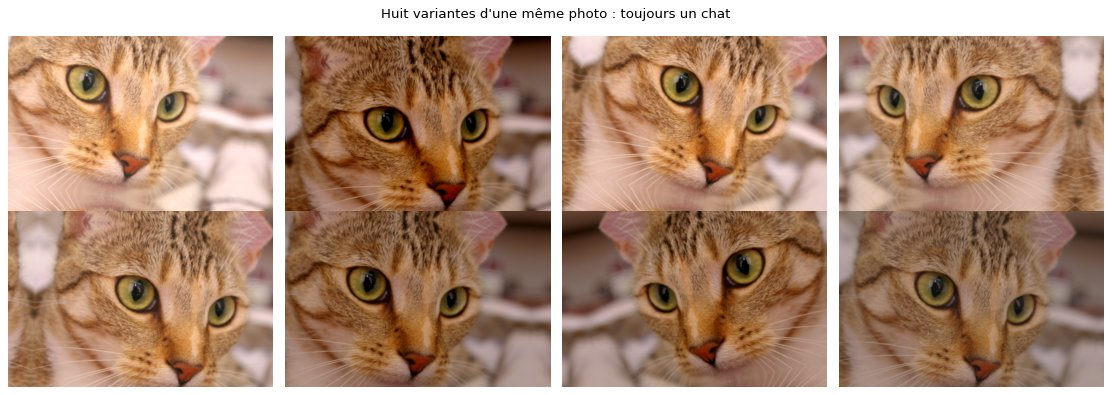

In [42]:
def augment(image, rng):
    """Une variante aléatoire : retournement, rotation, décalage, contraste et luminosité."""
    h, w = image.shape[:2]
    if rng.random() < 0.5:
        image = image[:, ::-1]                                    # retournement horizontal (une vue, voir À vous 1)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-15, 15), 1.0)
    M[:, 2] += (rng.uniform(-0.1, 0.1) * w, rng.uniform(-0.1, 0.1) * h)  # décalage d'au plus 10 %
    image = cv2.warpAffine(np.ascontiguousarray(image), M, (w, h), borderMode=cv2.BORDER_REFLECT)
    contrast, brightness = rng.uniform(0.7, 1.3), rng.uniform(-40, 40)
    return np.clip(contrast * image.astype(np.float64) + brightness, 0, 255).astype(np.uint8)


chelsea = data.chelsea()
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax in axes.ravel():
    ax.imshow(augment(chelsea, rng))
    ax.axis("off")
plt.suptitle("Huit variantes d'une même photo : toujours un chat")
plt.tight_layout()
plt.show()

**Une augmentation doit respecter les données.** Un chat retourné reste un chat; un « 2 » retourné n’est plus un 2, et un « 6 » tourné de 180° devient un 9. Pour les chiffres de la section F, nous n’utiliserons donc que de petites rotations et de petits décalages.

### À vous : Cutout

L’augmentation **Cutout** ([DeVries et Taylor, 2017](https://arxiv.org/abs/1708.04552)) cache un carré choisi au hasard. Le modèle ne peut plus compter sur un seul détail (les oreilles, par exemple) et doit regarder toute l’image.

Écrivez `cutout(image, size, rng)`. Il met à 0 un carré de `size × size` pixels, centré en un point tiré au hasard dans l’image. Comme dans l’article, le carré peut dépasser du bord : il est alors coupé. La fonction renvoie une **copie** et ne modifie pas l’image reçue.

In [43]:
def cutout(image, size, rng):
    # image : (H, W) ou (H, W, 3); size : côté du carré; rng : np.random.default_rng(...)
    # Votre code ici : remplacez pass, puis renvoyez une copie avec un carré mis à 0.
    pass

In [44]:
test_image = np.full((40, 60, 3), 200, dtype=np.uint8)
result = cutout(test_image, 16, np.random.default_rng(0))

if result is None:
    print("La fonction n'est pas encore complétée.")
else:
    assert (test_image == 200).all(), "L'image reçue ne doit pas être modifiée : travaillez sur une copie."
    assert result.shape == test_image.shape, "La forme ne doit pas changer."
    for seed in range(200):
        hidden = (cutout(test_image, 16, np.random.default_rng(seed)) == 0).all(axis=-1)
        rows, cols = np.nonzero(hidden)
        assert len(rows) > 0, "Le carré doit cacher au moins un pixel."
        assert hidden[rows.min() : rows.max() + 1, cols.min() : cols.max() + 1].all(), "La zone cachée doit être un rectangle plein."
        assert rows.max() - rows.min() < 16 and cols.max() - cols.min() < 16, "Le carré dépasse 16 × 16 pixels."
    print("Bravo ! Voici quelques variantes avec augment et cutout :")
    rng = np.random.default_rng(1)
    fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
    for ax in axes:
        ax.imshow(cutout(augment(chelsea, rng), 100, rng))
        ax.axis("off")
    plt.show()

La fonction n'est pas encore complétée.


<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
def cutout(image, size, rng):
    output = image.copy()
    h, w = image.shape[:2]
    center_y, center_x = rng.integers(0, h), rng.integers(0, w)  # n'importe où dans l'image
    top, left = center_y - size // 2, center_x - size // 2
    output[max(top, 0) : max(top + size, 0), max(left, 0) : max(left + size, 0)] = 0  # coupé au bord
    return output
```

`max(..., 0)` empêche un indice négatif, que NumPy compterait depuis la fin du tableau. Le dépassement à droite et en bas ne pose pas de problème : une tranche s’arrête d’elle-même au bord du tableau. Les auteurs ont constaté que laisser le carré dépasser du bord aidait le modèle : il voit aussi des exemples où seul un petit coin est caché.

Si vous avez essayé cette réponse, réexécutez la cellule de vérification.

</details>

## F. Des caractéristiques à un réseau convolutif

Jusqu’ici, **nous** avons choisi les noyaux : moyenne, gaussien, Sobel, laplacien. Un **réseau convolutif** (CNN) part de noyaux aléatoires et les **apprend** à partir de données étiquetées. Le cours résume ce changement : avant, on concevait l’extraction de caractéristiques à la main et seul le classifieur apprenait; avec un CNN, toute la chaîne apprend.

Dans cette section, nous entraînons un petit CNN sur **MNIST**, 70 000 chiffres manuscrits de 28 × 28 pixels. Puis nous posons deux questions :

1. Le réseau apprend-il des filtres qui ressemblent aux nôtres ?
2. Nos outils, les filtres et l’augmentation, l’aident-ils quand les données étiquetées sont rares ?

En local, cette section demande `uv sync --group vision`. Le réseau est petit : un processeur ordinaire suffit, sans GPU.

In [45]:
import contextlib
import io
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

torch.manual_seed(0)
print("PyTorch", torch.__version__)

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):  # masque la progression du téléchargement
    mnist_train = datasets.MNIST(DATA_DIR / "raw", train=True, download=True)
    mnist_test = datasets.MNIST(DATA_DIR / "raw", train=False, download=True)

X_train, y_train = mnist_train.data.numpy(), mnist_train.targets.numpy()  # des images uint8, comme avant
X_test, y_test = mnist_test.data.numpy(), mnist_test.targets.numpy()
print(f"Entraînement : {X_train.shape} {X_train.dtype} | test : {X_test.shape}")
print("Images par chiffre :", np.bincount(y_train))

PyTorch 2.14.0
Entraînement : (60000, 28, 28) uint8 | test : (10000, 28, 28)
Images par chiffre : [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


Ce sont des images comme les autres : des tableaux `uint8`, un chiffre blanc sur fond noir. Les dix classes sont à peu près équilibrées. Avant tout modèle, regardons les données : un exemple de chaque chiffre, puis la **moyenne** de tous les exemples de chaque chiffre.

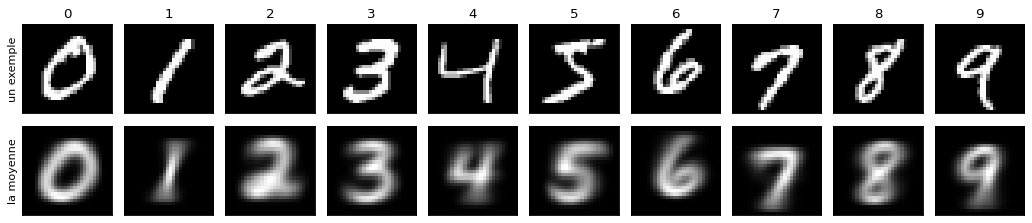

In [46]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for digit in range(10):
    examples = X_train[y_train == digit]
    axes[0, digit].imshow(examples[0], cmap="gray")
    axes[1, digit].imshow(examples.mean(axis=0), cmap="gray")
    axes[0, digit].set_title(str(digit))
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("un exemple")
axes[1, 0].set_ylabel("la moyenne")
plt.tight_layout()
plt.show()

Les moyennes sont floues : personne n’écrit un chiffre exactement au même endroit, avec la même taille et la même inclinaison. C’est la difficulté du problème.

### Les pixels sont de mauvaises caractéristiques

Le classifieur le plus simple, celui des *k* plus proches voisins de la démo 3, compare directement les pixels. Le cours le dit sans détour : on ne l’utilise jamais sur des images, car une distance entre pixels ne dit pas grand-chose. Vérifions-le en décalant les chiffres de test de 3 pixels vers la droite.

In [47]:
from sklearn.neighbors import KNeighborsClassifier

n_reference = 10_000
knn = KNeighborsClassifier(n_neighbors=1).fit(X_train[:n_reference].reshape(n_reference, -1), y_train[:n_reference])

test_digits = X_test[:1000]
shifted_digits = np.stack([shift_image(digit, 0, 3) for digit in test_digits])  # 3 pixels vers la droite
for name, images in [("chiffres de test", test_digits), ("décalés de 3 pixels", shifted_digits)]:
    score = knn.score(images.reshape(len(images), -1), y_test[:1000])
    print(f"1 plus proche voisin sur les pixels, {name:20} : {score:.1%}")

1 plus proche voisin sur les pixels, chiffres de test     : 92.0%
1 plus proche voisin sur les pixels, décalés de 3 pixels  : 41.1%


Un décalage de 3 pixels, à peine visible, fait chuter le score d’environ 92 % à 41 %. Pour la distance entre pixels, un chiffre décalé ressemble moins à lui-même qu’à un autre chiffre. Regardons un exemple. Notez la conversion en réels : une soustraction en `uint8` déborderait (section A).

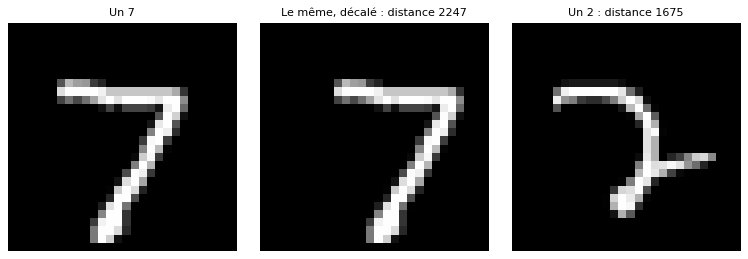

In [48]:
digit, label = X_test[0].astype(np.float64), y_test[0]
moved = shift_image(X_test[0], 0, 3).astype(np.float64)
others = X_train[:n_reference][y_train[:n_reference] != label].astype(np.float64)
distances = np.linalg.norm(others - digit, axis=(1, 2))
closest_other = others[distances.argmin()]
other_label = y_train[:n_reference][y_train[:n_reference] != label][distances.argmin()]

show(digit, moved, closest_other,
     titles=[f"Un {label}", f"Le même, décalé : distance {np.linalg.norm(moved - digit):.0f}",
             f"Un {other_label} : distance {distances.min():.0f}"])

Il faut des caractéristiques qui détectent un trait **où qu’il soit**. Les filtres de la section C le font, puisqu’ils sont équivariants. C’est exactement ce que contient un CNN.

### Du filtre à la couche de convolution

Dans PyTorch, une **couche de convolution** (`nn.Conv2d`) contient des noyaux, appelés ses **poids**. Copions notre noyau de Sobel dans une couche, et comparons le résultat à OpenCV.

PyTorch range les images dans un tenseur de forme `(N, C, H, W)` : le nombre d’images, de canaux, la hauteur et la largeur. Pour `camera` : une image, un canal.

In [49]:
sobel_layer = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    sobel_layer.weight[0, 0] = torch.tensor(SOBEL_X, dtype=torch.float32)  # les poids = notre noyau

image_tensor = torch.tensor(camera, dtype=torch.float32)[None, None]  # (N, C, H, W) = (1, 1, 512, 512)
with torch.no_grad():
    from_pytorch = sobel_layer(image_tensor)[0, 0].numpy()
from_opencv = cv2.filter2D(camera.astype(np.float32), -1, SOBEL_X.astype(np.float32), borderType=cv2.BORDER_CONSTANT)

print("Forme de l'entrée :", tuple(image_tensor.shape), "| forme de la sortie :", tuple(sobel_layer(image_tensor).shape))
print("Même résultat qu'OpenCV :", np.allclose(from_pytorch, from_opencv, atol=1e-3))

Forme de l'entrée : (1, 1, 512, 512) | forme de la sortie : (1, 1, 512, 512)
Même résultat qu'OpenCV : True


Même résultat : PyTorch calcule lui aussi une **corrélation**, comme `cv2.filter2D` (section C). Une couche `nn.Conv2d(1, 8, 3)` contient simplement **8 noyaux** de 3 × 3 et produit 8 images filtrées, appelées **cartes de caractéristiques** (*feature maps*) ou canaux. La seule différence avec nos filtres : ses poids commencent au hasard et sont **appris** par descente de gradient.

### Un petit CNN, entraîné de zéro

Notre réseau enchaîne deux blocs, puis une couche linéaire qui produit un score par chiffre :

| Étape | Rôle | Taille des cartes |
|---|---|---|
| `conv1` : 8 noyaux de 3 × 3 | détecter des motifs simples | 8 × 28 × 28 |
| ReLU, puis *max pooling* 2 × 2 | garder les réponses positives, puis le maximum de chaque carré de 2 × 2 | 8 × 14 × 14 |
| `conv2` : 16 noyaux de 3 × 3 sur les 8 cartes | combiner les motifs | 16 × 14 × 14 |
| ReLU, puis *max pooling* 2 × 2 | | 16 × 7 × 7 |
| `classifier` : couche linéaire | un score par chiffre | 10 |

Le *max pooling* répond à la question « le motif est-il présent dans cette zone ? » sans dire exactement où. Il réduit aussi la taille des cartes de moitié.

Une étape vient des **données** : comme à la démo 4, on centre et on réduit les pixels avec la moyenne et l’écart-type calculés **sur l’entraînement seulement**.

In [50]:
MEAN, STD = float(X_train.mean() / 255), float(X_train.std() / 255)  # calculés sur l'entraînement seulement


def to_tensor(images):
    """(N, 28, 28) en uint8 -> tenseur (N, 1, 28, 28) centré et réduit."""
    return ((torch.tensor(images, dtype=torch.float32) / 255 - MEAN) / STD).unsqueeze(1)


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.classifier = nn.Linear(16 * 7 * 7, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)  # 28 × 28 -> 14 × 14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)  # 14 × 14 -> 7 × 7
        return self.classifier(x.flatten(1))


def train(model, images, labels, steps, augment=None, batch_size=64, seed=0):
    rng = np.random.default_rng(seed)
    trainable = [p for p in model.parameters() if p.requires_grad]  # les poids figés ne sont pas appris
    optimizer = torch.optim.Adam(trainable, lr=2e-3)
    model.train()
    for _ in range(steps):
        batch = rng.integers(0, len(images), batch_size)  # un lot tiré au hasard
        inputs = images[batch]
        if augment is not None:
            inputs = np.stack([augment(image, rng) for image in inputs])
        loss = F.cross_entropy(model(to_tensor(inputs)), torch.tensor(labels[batch]))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model


@torch.no_grad()
def accuracy(model, images, labels):
    model.eval()
    return (model(to_tensor(images)).argmax(dim=1).numpy() == labels).mean()


torch.manual_seed(0)
model = SmallCNN()
print(f"{spaced(sum(p.numel() for p in model.parameters()))} paramètres")

start = time.time()
train(model, X_train, y_train, steps=len(X_train) // 64)  # une époque : chaque image vue environ une fois
print(f"Entraînement : {time.time() - start:.0f} s")
print(f"Accuracy sur les 10 000 chiffres de test : {accuracy(model, X_test, y_test):.1%}")

9 098 paramètres


Entraînement : 7 s
Accuracy sur les 10 000 chiffres de test : 97.4%


Environ 97 % après une seule époque, avec moins de 10 000 paramètres et quelques secondes sur un processeur.

### Qu’a-t-il appris ?

Regardons les 8 noyaux de `conv1`. Pour chacun, cherchons parmi **nos** noyaux de 3 × 3 celui qui lui ressemble le plus, en mesurant la similarité cosinus de leurs poids. Le signe ne compte pas : un noyau et son opposé détectent le même contour.

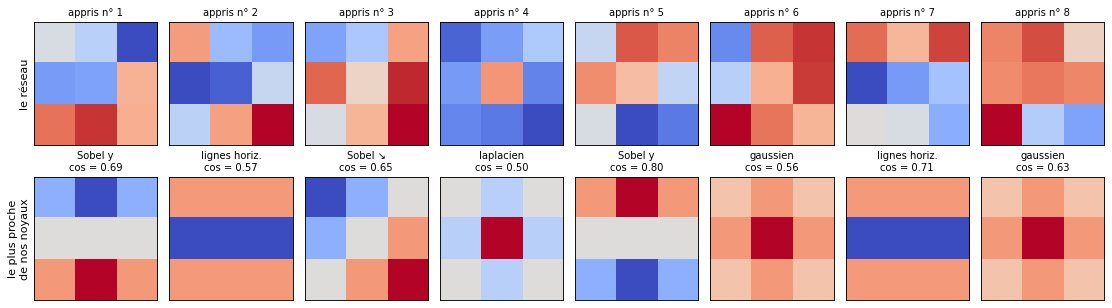

In [51]:
OUR_FILTERS = {
    "Sobel x": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "Sobel y": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "Sobel ↗": [[0, 1, 2], [-1, 0, 1], [-2, -1, 0]],
    "Sobel ↘": [[2, 1, 0], [1, 0, -1], [0, -1, -2]],
    "laplacien": [[0, 1, 0], [1, -4, 1], [0, 1, 0]],
    "gaussien": [[1, 2, 1], [2, 4, 2], [1, 2, 1]],
    "lignes horiz.": [[-1, -1, -1], [2, 2, 2], [-1, -1, -1]],
    "lignes vert.": [[-1, 2, -1], [-1, 2, -1], [-1, 2, -1]],
}
our_bank = np.array(list(OUR_FILTERS.values()), dtype=np.float32)
our_bank /= np.linalg.norm(our_bank.reshape(8, -1), axis=1)[:, None, None]  # même norme pour tous

learned = model.conv1.weight.detach().numpy()[:, 0]                         # (8, 3, 3)
learned_unit = learned / np.linalg.norm(learned.reshape(8, -1), axis=1)[:, None, None]
similarity = learned_unit.reshape(8, -1) @ our_bank.reshape(8, -1).T         # similarité cosinus, (8, 8)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    best = np.abs(similarity[i]).argmax()
    sign = np.sign(similarity[i, best])
    for ax, kernel, title in [(axes[0, i], learned[i], f"appris n° {i + 1}"),
                              (axes[1, i], sign * our_bank[best], f"{list(OUR_FILTERS)[best]}\ncos = {abs(similarity[i, best]):.2f}")]:
        limit = np.abs(kernel).max()
        ax.imshow(kernel, cmap="coolwarm", vmin=-limit, vmax=limit)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_ylabel("le réseau")
axes[1, 0].set_ylabel("le plus proche\nde nos noyaux")
plt.tight_layout()
plt.show()

Plusieurs noyaux appris ressemblent nettement à des détecteurs de contours de la section D, du type Sobel ou « lignes », avec un cosinus qui monte jusqu’à 0,7 ou 0,8. D’autres ressemblent beaucoup moins à nos noyaux. Le réseau n’a aucune raison de retrouver exactement notre liste : il cherche les noyaux qui aident à reconnaître des chiffres. Mais l’idée est la même : **comparer un pixel à ses voisins**.

Regardons ce que ces 8 noyaux produisent sur un chiffre : 8 cartes de caractéristiques.

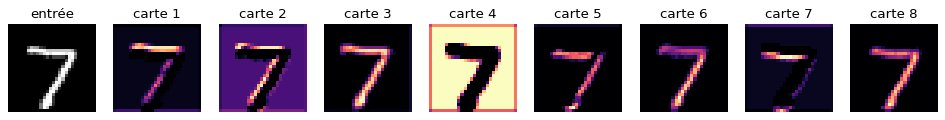

In [52]:
digit = X_test[0]
with torch.no_grad():
    maps = F.relu(model.conv1(to_tensor(digit[None])))[0].numpy()  # les 8 cartes après conv1 et ReLU

fig, axes = plt.subplots(1, 9, figsize=(15, 2))
axes[0].imshow(digit, cmap="gray")
axes[0].set_title("entrée")
for i, ax in enumerate(axes[1:]):
    ax.imshow(maps[i], cmap="magma")
    ax.set_title(f"carte {i + 1}")
for ax in axes:
    ax.axis("off")
plt.show()

Chaque carte allume une partie différente du trait : certains bords, l’intérieur, le fond. Ce sont les caractéristiques que `conv2`, puis le classifieur, combinent.

### Équivariance des cartes, invariance de la prédiction

Le cours résume le but ainsi : des caractéristiques **équivariantes** et des prédictions **invariantes**. Décalons le chiffre de 2 pixels. Les cartes de `conv1` devraient se décaler avec lui (section C), et la prédiction ne devrait pas changer.

In [53]:
moved_digit = shift_image(digit, 2, 2)  # 2 pixels vers le bas et vers la droite
with torch.no_grad():
    maps_moved = F.relu(model.conv1(to_tensor(moved_digit[None])))[0].numpy()
    probabilities = F.softmax(model(to_tensor(np.stack([digit, moved_digit]))), dim=1).numpy()

# Les cartes du chiffre décalé, recalées de 2 pixels, comparées à l'intérieur (loin des bords)
print("Cartes décalées avec le chiffre :", np.allclose(maps_moved[:, 3:-1, 3:-1], maps[:, 1:-3, 1:-3], atol=1e-5))
for name, p in zip(["original", "décalé"], probabilities):
    print(f"Chiffre {name:9}: prédit {p.argmax()}, avec une probabilité de {p.max():.1%}")

Cartes décalées avec le chiffre : True
Chiffre original : prédit 7, avec une probabilité de 100.0%
Chiffre décalé   : prédit 7, avec une probabilité de 98.6%


Le réseau n’est pas pour autant insensible à tous les déplacements. Construisons un jeu de test plus difficile : chaque chiffre de test tourné de ±20° au plus et décalé de 3 pixels au plus.

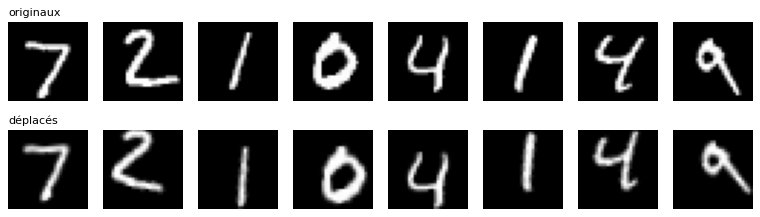

Accuracy sur les chiffres de test : 97.4%
Accuracy sur les chiffres déplacés : 69.2%


In [54]:
def move_digit(image, angle, dx, dy):
    """Tourne un chiffre de 28 × 28 autour de son centre, puis le décale."""
    M = cv2.getRotationMatrix2D((13.5, 13.5), angle, 1.0)
    M[:, 2] += (dx, dy)
    return cv2.warpAffine(image, M, (28, 28))


rng = np.random.default_rng(0)
X_test_moved = np.stack([move_digit(d, rng.uniform(-20, 20), *rng.integers(-3, 4, size=2)) for d in X_test])

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(X_test[i], cmap="gray")
    axes[1, i].imshow(X_test_moved[i], cmap="gray")
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("originaux", loc="left", fontsize=10)
axes[1, 0].set_title("déplacés", loc="left", fontsize=10)
plt.show()

print(f"Accuracy sur les chiffres de test : {accuracy(model, X_test, y_test):.1%}")
print(f"Accuracy sur les chiffres déplacés : {accuracy(model, X_test_moved, y_test):.1%}")

L’accuracy chute d’environ 97 % à 69 %. Le *max pooling* absorbe les petits décalages, mais pas une rotation de 20° combinée à un décalage de 3 pixels. Le réseau n’a vu que les chiffres de MNIST, bien centrés et presque droits : **un modèle ne sait que ce que ses données d’entraînement lui montrent.**

### Quand les étiquettes manquent

Nous avions 60 000 chiffres étiquetés. Dans un vrai projet, étiqueter coûte cher : le cours mentionne les entreprises payées pour le faire. Supposons que nous n’ayons que **500 chiffres étiquetés**.

Deux outils des sections précédentes peuvent aider :

- l’**augmentation** (section E) : de petites rotations et de petits décalages, sans retournement;
- **nos filtres** (sections C et D) comme première couche, à la place de noyaux appris (exercice À vous ci-dessous).

Chaque expérience entraîne le réseau sur 500 chiffres tirés au hasard, trois fois avec des tirages différents, puis donne la moyenne des accuracy.

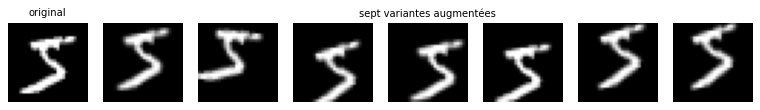

(21 s)

                                     test   déplacés
(a) tout appris                     92.1%      48.1%
(c) tout appris + augmentation      95.0%      88.0%


In [55]:
N_LABELS = 500


def augment_digit(image, rng):
    """Rotation de ±15° au plus et décalage de ±3 pixels au plus. Pas de retournement."""
    return move_digit(image, rng.uniform(-15, 15), *rng.integers(-3, 4, size=2))


def make_cnn(seed):
    torch.manual_seed(seed)
    return SmallCNN()


def run_experiment(make_model, augment=None, n_labels=N_LABELS, seeds=(0, 1, 2)):
    scores = []
    for seed in seeds:
        subset = np.random.default_rng(100 + seed).choice(len(X_train), n_labels, replace=False)
        model = train(make_model(seed), X_train[subset], y_train[subset], steps=400, augment=augment, seed=seed)
        scores.append((accuracy(model, X_test, y_test), accuracy(model, X_test_moved, y_test)))
    return np.mean(scores, axis=0)


def print_results(results):
    print(f"{'':32} {'test':>8} {'déplacés':>10}")
    for name, (clean, moved) in results.items():
        print(f"{name:32} {clean:8.1%} {moved:10.1%}")


rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
axes[0].imshow(X_train[0], cmap="gray")
axes[0].set_title("original", fontsize=9)
axes[4].set_title("sept variantes augmentées", fontsize=9)
for ax in axes[1:]:
    ax.imshow(augment_digit(X_train[0], rng), cmap="gray")
for ax in axes:
    ax.axis("off")
plt.show()

start = time.time()
results = {
    "(a) tout appris": run_experiment(make_cnn),
    "(c) tout appris + augmentation": run_experiment(make_cnn, augment=augment_digit),
}
print(f"({time.time() - start:.0f} s)\n")
print_results(results)

Avec 500 chiffres seulement, l’accuracy tombe à environ 92 % sur le test et 48 % sur les chiffres déplacés. L’augmentation ajoute environ 3 points sur le test, et **40 points** sur les chiffres déplacés : pendant l’entraînement, le réseau a vu des chiffres tournés et décalés. Aucune étiquette supplémentaire n’a été nécessaire. Nous avons fabriqué de nouveaux exemples à partir de ceux que nous avions.

### À vous : nos filtres comme première couche

Et si `conv1` utilisait **nos** noyaux au lieu de les apprendre ? Complétez `make_cnn_with_our_filters` :

1. copiez `OUR_BANK`, nos 8 noyaux de 3 × 3, dans `model.conv1.weight`;
2. **figez** ces poids pour que l’entraînement ne les modifie pas.

La fonction `train` n’optimise que les paramètres pour lesquels `requires_grad` vaut `True`. Le biais de `conv1` reste appris : le réseau garde le choix du seuil à partir duquel un contour compte.

In [56]:
OUR_BANK = torch.tensor(our_bank).unsqueeze(1)  # (8, 1, 3, 3) : 8 noyaux, 1 canal d'entrée


def make_cnn_with_our_filters(seed):
    torch.manual_seed(seed)
    model = SmallCNN()
    # Votre code ici : copiez OUR_BANK dans model.conv1.weight, puis empêchez ces poids d'être appris.
    return model

In [57]:
model_test = make_cnn_with_our_filters(0)

if not torch.allclose(model_test.conv1.weight, OUR_BANK):
    print("La fonction n'est pas encore complétée : conv1 ne contient pas nos noyaux.")
else:
    assert not model_test.conv1.weight.requires_grad, "Les noyaux doivent rester fixes : requires_grad doit valoir False."
    results["(b) nos filtres, figés"] = run_experiment(make_cnn_with_our_filters)
    print_results(results)

La fonction n'est pas encore complétée : conv1 ne contient pas nos noyaux.


<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
def make_cnn_with_our_filters(seed):
    torch.manual_seed(seed)
    model = SmallCNN()
    with torch.no_grad():                         # une copie, pas une étape d'apprentissage
        model.conv1.weight.copy_(OUR_BANK)
    model.conv1.weight.requires_grad_(False)       # train n'optimisera plus ces poids
    return model
```

Avec nos noyaux figés, on obtient environ 93,0 % sur le test et 51,5 % sur les chiffres déplacés, contre 92,1 % et 48,1 % pour le réseau qui apprend tout. Le gain est petit, environ un point, mais il revient à chaque tirage. L’entraînement est aussi un peu plus rapide : PyTorch n’a plus à calculer le gradient des poids de `conv1`.

Pour aller plus loin :

- avec 5 000 étiquettes, comparez `run_experiment(make_cnn, n_labels=5000)` et `run_experiment(make_cnn_with_our_filters, n_labels=5000)`. Sur les chiffres de test, l’écart se réduit à moins d’un demi-point;
- combinez nos filtres et l’augmentation : `run_experiment(make_cnn_with_our_filters, augment=augment_digit)`.

Si vous avez essayé cette réponse, réexécutez la cellule de vérification.

</details>

### Ce que montre l’expérience

| Avec 500 étiquettes | Chiffres de test | Chiffres déplacés |
|---|---|---|
| (a) tout appris | ≈ 92 % | ≈ 48 % |
| (b) nos filtres, figés | ≈ 93 % | ≈ 51 % |
| (c) tout appris + augmentation | ≈ 95 % | ≈ 88 % |

Deux leçons, toutes deux liées aux **données** :

- **Nos filtres aident un peu.** Ils apportent au réseau une connaissance que nous avions déjà : les contours comptent. Avec peu d’exemples, c’est autant de moins à apprendre. Avec plus d’exemples, le réseau trouve lui-même des noyaux presque aussi utiles, et l’avantage se réduit.
- **L’augmentation aide beaucoup**, surtout sur les chiffres déplacés. Elle montre au réseau les variations qu’il rencontrera, sans aucune étiquette de plus. Pour améliorer un modèle de vision, c’est souvent le moyen le plus simple : savoir quelles variations des images ne changent pas leur classe, puis les montrer au modèle.

### Et après ?

Notre CNN a moins de 10 000 paramètres et a vu 60 000 petites images. En 2012, **AlexNet** en avait 60 millions et avait vu les 1,2 million de photos étiquetées d’**ImageNet**. C’est ce jeu de données, plus que l’architecture, qui a rendu ce saut possible. Les noyaux de sa première couche ressemblent étonnamment aux nôtres : des détecteurs de contours orientés et des taches de couleur.

Depuis, la tendance continue du côté des données. Le **Vision Transformer** découpe l’image en petits carrés et les fait communiquer par l’attention : c’est la section G de la démo 5. Les **modèles de fondation**, entraînés sur des centaines de millions d’images, décrivent une photo en texte ou découpent n’importe quel objet sans nouvel entraînement. Le cours rappelle leurs limites : ils sont lourds, coûteux, sensibles à la formulation de la question et gênés par les occlusions.

## À retenir

- Une image est un tableau `uint8` : attention au **BGR**, aux débordements et à `(largeur, hauteur)`.
- Une **opération ponctuelle** regarde un pixel; un **filtre** regarde son voisinage. Un filtre linéaire est une **convolution** avec un noyau, et il est **équivariant** par translation.
- Les **contours** et les **gradients** sont des caractéristiques plus compactes et plus parlantes que les pixels. Pour les trouver, on **lisse avant de dériver**.
- Déformer déplace les pixels sans changer leurs valeurs; c’est la base de l’**augmentation de données**, qui doit respecter les classes.
- Une couche de convolution est un ensemble de filtres dont les poids sont **appris**. Avec peu d’étiquettes, l’augmentation de données l’aide beaucoup; nos filtres faits à la main, un peu.

## Pour aller plus loin

- La documentation d’OpenCV : [tutoriels OpenCV-Python](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html), et la [galerie d’exemples de scikit-image](https://scikit-image.org/docs/stable/auto_examples/).
- [*Image Kernels explained visually*](https://setosa.io/ev/image-kernels/), de Setosa : essayez des noyaux sur vos propres images, dans le navigateur.
- [CNN Explainer](https://poloclub.github.io/cnn-explainer/) : un petit CNN dont on peut inspecter chaque couche.
- Le cours [CS231n de Stanford sur les réseaux convolutifs](https://cs231n.github.io/convolutional-networks/), cité dans le cours.

Ce notebook reprend les thèmes du laboratoire 9 d’IFT6758 (automne 2020) sur OpenCV, ainsi que ses deux exercices (BGR → RGB et Cutout), réécrits pour le cours actuel.